
# Ethereum Accumulation Zones
### Machine Learning & Regression Analysis

**Kurs:** Statistisk programmering och maskininlärning  
**Projekt:** Grupparbete – Nackademin

### Projektets syfte

Syftet är att undersöka om regressionsbaserade prisband kan identifiera historiska ackumulationszoner för Ethereum som har varit förknippade med gynnsam långsiktig avkastning.

Projektet omfattar:
- Datainsamling och datavalidering
- Exploratory Data Analysis (EDA)
- Statistisk analys och Feature Engineering
- Regression och Machine Learning
- Model Evaluation och Backtesting
- Visualisering i Streamlit

**Datakälla:** Coin Metrics Community API  
**Tillgångar:** Ethereum (ETH) och Bitcoin (BTC)  
**Tidsperiod:** 2015–2026  
**Frekvens:** Dagliga observationer


### Projektmiljö

Vi kontrollerar att notebooken använder rätt Python-miljö och bibliotek för att säkerställa att analysen kan reproduceras.

In [1]:
import sys
import pandas as pd

print("Python:", sys.version)
print("Python path:", sys.executable)
print("Pandas:", pd.__version__)

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:30:20) [Clang 20.1.8 ]
Python path: /Users/sajiabushagra/ML-Gruppprojekt/.venv/bin/python
Pandas: 3.1.0



##  Datainsamling (Data Collection)

Historiska prisdata för Ethereum (ETH) och Bitcoin (BTC) har hämtats från Coin Metrics Community API med gruppens gemensamma Python-skript.

Datan har sparats som CSV-filer och lästs in i pandas för vidare bearbetning och analys.

Genom att använda samma datakälla för båda tillgångarna får vi en mer konsekvent grund för projektets analyser.


In [2]:
import pandas as pd

# Load raw datasets from the project directory
eth = pd.read_csv("/Users/sajiabushagra/ML-Gruppprojekt/data/raw/eth_api.csv")
btc = pd.read_csv("/Users/sajiabushagra/ML-Gruppprojekt/data/raw/btc_api.csv")

# Check data quality
for name, df in [("ETH", eth), ("BTC", btc)]:
    print(f"\n{name}")
    print("Rows and columns:", df.shape)
    print("Columns:", df.columns.tolist())
    print("First date:", df["time"].min())
    print("Last date:", df["time"].max())
    print("Missing prices:", df["PriceUSD"].isna().sum())


ETH
Rows and columns: (4104, 2)
Columns: ['time', 'PriceUSD']
First date: 2015-08-08 00:00:00+00:00
Last date: 2026-11-01 00:00:00+00:00
Missing prices: 0

BTC
Rows and columns: (4323, 2)
Columns: ['time', 'PriceUSD']
First date: 2015-01-01 00:00:00+00:00
Last date: 2026-11-01 00:00:00+00:00
Missing prices: 0



## Datavalidering (Data Validation)

Vi undersöker datakvaliteten genom att kontrollera saknade värden, dubbletter, ogiltiga priser och saknade kalenderdagar.


In [3]:
# Check missing calendar dates and consecutive identical prices
for name, df in [("ETH", eth), ("BTC", btc)]:
    dates = pd.to_datetime(df["time"], utc=True)

    expected_dates = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq="D"
    )

    missing_dates = expected_dates.difference(dates)
    unchanged_prices = df["PriceUSD"].eq(df["PriceUSD"].shift())

    print(f"\n{name}")
    print("Missing calendar dates:", len(missing_dates))
    print("Consecutive unchanged prices:", unchanged_prices.sum())


ETH
Missing calendar dates: 0
Consecutive unchanged prices: 5

BTC
Missing calendar dates: 0
Consecutive unchanged prices: 0


In [4]:
# Identify days when ETH price was unchanged
unchanged = eth["PriceUSD"].eq(eth["PriceUSD"].shift())

# Display affected dates and prices
display(eth.loc[unchanged, ["time", "PriceUSD"]])

,time,PriceUSD
1,2015-08-09 00:00:00+00:00,1.199990
2,2015-08-10 00:00:00+00:00,1.199990
27,2015-09-04 00:00:00+00:00,1.233570
44,2015-09-21 00:00:00+00:00,0.941160
63,2015-10-10 00:00:00+00:00,0.635191



### Resultat

- **ETH:** 4 104 observationer (2015-08-08 till 2026-11-01).
- **BTC:** 4 323 observationer (2015-01-01 till 2026-11-01).
- Inga saknade värden, dubbletter eller saknade kalenderdagar.
- Inga ogiltiga priser identifierades.
- ETH hade 5 observationer med oförändrat pris jämfört med föregående dag, samtliga under 2015.

### Slutsats

Inga större datakvalitetsproblem identifierades. De oförändrade ETH-priserna behålls eftersom vi saknar belägg för att de är felaktiga.

Datan bedöms vara tillräckligt komplett för fortsatt bearbetning och analys.

## 3. Datarensning (Data Cleaning)

Vi använder gruppens gemensamma bearbetade dataset och kontrollerar att ETH- och BTC-priserna är korrekt sammanfogade.

### 3.1 Kontroll av dataintegritet

Vi jämför priserna med originaldata för att säkerställa att datarensningen inte har förändrat prisinformationen.

In [5]:
# Load the shared cleaned dataset
cleaned = pd.read_csv("../data/processed/crypto_dataset.csv")

# Examine its structure and first observations
print("Shape:", cleaned.shape)
print("Columns:", cleaned.columns.tolist())

display(cleaned.head())

Shape: (4104, 3)
Columns: ['Date', 'ETH_Price', 'BTC_Price']


,Date,ETH_Price,BTC_Price
0,2015-08-08,1.19999,261.450276
1,2015-08-09,1.19999,266.342020
2,2015-08-10,1.19999,264.928825
3,2015-08-11,0.99000,271.421736
4,2015-08-12,1.28800,268.143868


In [6]:
# Prepare original datasets for comparison
eth_original = eth.rename(columns={"time": "Date", "PriceUSD": "ETH_Price"}).copy()
btc_original = btc.rename(columns={"time": "Date", "PriceUSD": "BTC_Price"}).copy()

# Standardize dates for comparison
for df in [eth_original, btc_original, cleaned]:
    df["Date"] = pd.to_datetime(df["Date"], utc=True)

# Reconstruct the dataset directly from the original API data
expected = eth_original.merge(
    btc_original,
    on="Date",
    how="inner",
    validate="one_to_one"
)

# Compare original prices against cleaned prices
comparison = cleaned.merge(
    expected,
    on="Date",
    suffixes=("_cleaned", "_original"),
    validate="one_to_one"
)

print("Original merged rows:", len(expected))
print("Cleaned rows:", len(cleaned))
print("Matched rows:", len(comparison))

print("ETH prices unchanged:",
      (comparison["ETH_Price_cleaned"] == comparison["ETH_Price_original"]).all())

print("BTC prices unchanged:",
      (comparison["BTC_Price_cleaned"] == comparison["BTC_Price_original"]).all())

Original merged rows: 4104
Cleaned rows: 4104
Matched rows: 4104
ETH prices unchanged: False
BTC prices unchanged: False


In [7]:
import numpy as np

# Calculate absolute differences between cleaned and original prices
for asset in ["ETH", "BTC"]:
    difference = (
        comparison[f"{asset}_Price_cleaned"]
        - comparison[f"{asset}_Price_original"]
    ).abs()

    print(f"\n{asset}")
    print("Maximum difference:", difference.max())
    print("Different values:", (difference > 0).sum())
    print("Approximately equal:",
          np.allclose(
              comparison[f"{asset}_Price_cleaned"],
              comparison[f"{asset}_Price_original"],
              rtol=1e-10,
              atol=1e-10
          ))


ETH
Maximum difference: 5.684341886080802e-14
Different values: 3
Approximately equal: True

BTC
Maximum difference: 3.637978807091713e-12
Different values: 6
Approximately equal: True


### Resultat
- Samtliga 4 104 observationer matchades korrekt.
- ETH hade 3 minimala numeriska avvikelser.
- BTC hade 6 minimala numeriska avvikelser.
- Båda prisserierna godkändes med `np.allclose()`.

Skillnaderna är extremt små och beror sannolikt på flyttalsprecision (floating-point precision).

### Slutsats
Datarensningen har bevarat prisinformationen inom numerisk tolerans. Det bearbetade datasetet kan därför användas som gemensam grund för projektets fortsatta analyser.

In [8]:
display(cleaned)


,Date,ETH_Price,BTC_Price
0,2015-08-08 00:00:00+00:00,1.199990,261.450276
1,2015-08-09 00:00:00+00:00,1.199990,266.342020
2,2015-08-10 00:00:00+00:00,1.199990,264.928825
3,2015-08-11 00:00:00+00:00,0.990000,271.421736
4,2015-08-12 00:00:00+00:00,1.288000,268.143868
...,...,...,...
4099,2026-10-28 00:00:00+00:00,2356.988509,81237.437826
4100,2026-10-29 00:00:00+00:00,2256.031994,78193.426404
4101,2026-10-30 00:00:00+00:00,2240.229980,77109.590747
4102,2026-10-31 00:00:00+00:00,2252.073358,77401.017287



##  Exploratory Data Analysis (EDA)

Syftet med EDA är att förstå datans egenskaper, identifiera historiska mönster och upptäcka eventuella problem innan vi bygger våra ML-modeller.

Vi undersöker bland annat prisutveckling, avkastning, volatilitet, korrelation mellan ETH och BTC samt glidande medelvärden.

### Historisk prisutveckling – Ethereum

Vi börjar med att visualisera Ethereums historiska prisutveckling i USD.

Syftet är att identifiera långsiktiga trender, kraftiga prisrörelser och marknadscykler. Analysen hjälper oss även att förstå varför logaritmiska transformationer kan vara relevanta för vår regressionsmodell.


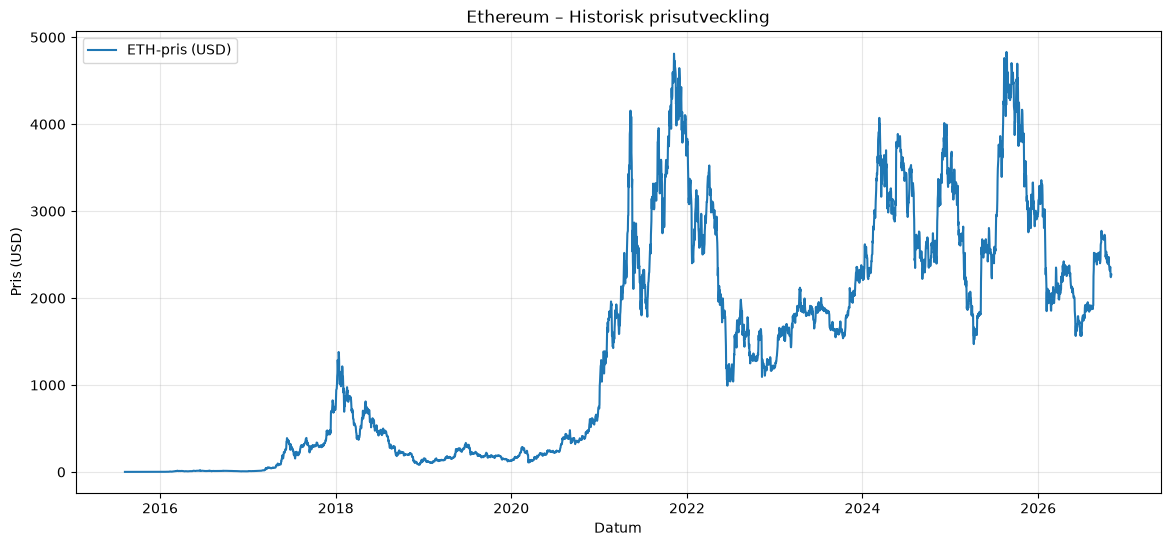

In [9]:

import matplotlib.pyplot as plt

# Skapa en kopia av vårt gemensamma dataset
df = cleaned.copy()

# Konvertera datumkolumnen till datetime
df["Date"] = pd.to_datetime(df["Date"])

# Visualisera Ethereums historiska prisutveckling
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["ETH_Price"],
    label="ETH-pris (USD)"
)

plt.title("Ethereum – Historisk prisutveckling")
plt.xlabel("Datum")
plt.ylabel("Pris (USD)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Ethereum uppvisar stora prisvariationer och flera tydliga marknadscykler med kraftiga uppgångar och nedgångar.

Den linjära prisskalan gör det svårt att urskilja prisrörelser under de tidiga åren eftersom senare prisnivåer är betydligt högre.

**Slutsats:** Ethereums prisutveckling är volatil och förändras kraftigt över tid. En logaritmisk skala bör undersökas för att bättre jämföra relativa prisförändringar mellan olika perioder.


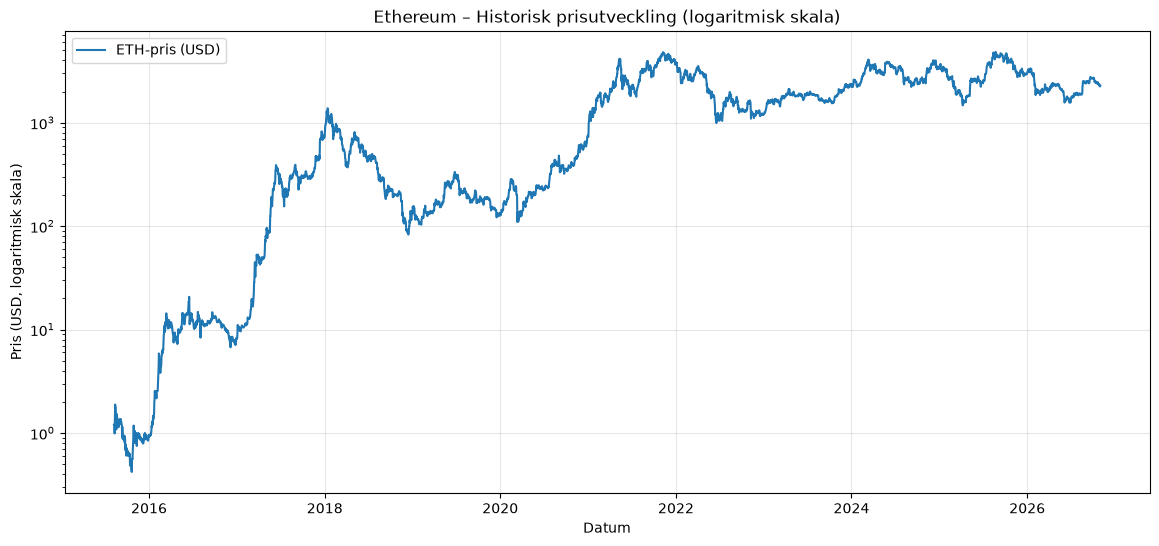

In [10]:

# Visualisera ETH-priset med logaritmisk skala
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["ETH_Price"],
    label="ETH-pris (USD)"
)

plt.yscale("log")

plt.title("Ethereum – Historisk prisutveckling (logaritmisk skala)")
plt.xlabel("Datum")
plt.ylabel("Pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Den logaritmiska skalan gör Ethereums tidiga prisutveckling betydligt tydligare jämfört med den linjära skalan.

Vi kan identifiera kraftiga uppgångar och nedgångar under flera marknadsperioder. Den relativa tillväxten var särskilt stor under de tidiga åren, medan prisutvecklingen senare visar perioder med långsammare tillväxt och stora variationer.

**Slutsats:** Logaritmisk skala är lämplig för att analysera Ethereums långsiktiga prisutveckling. Detta motiverar att vi senare undersöker regression på logaritmerade priser, men visar ännu inte vilken regressionsmodell som passar bäst.



### Daglig avkastning (Daily Returns)

Vi beräknar Ethereums dagliga procentuella avkastning för att undersöka prisförändringar oberoende av den absoluta prisnivån.

Det hjälper oss att identifiera extrema prisrörelser och förstå volatiliteten i marknaden.


count    4103.000000
mean        0.323092
std         5.305332
min       -43.198894
25%        -2.060980
50%         0.047609
75%         2.297936
max        46.335404
Name: ETH_Return, dtype: float64

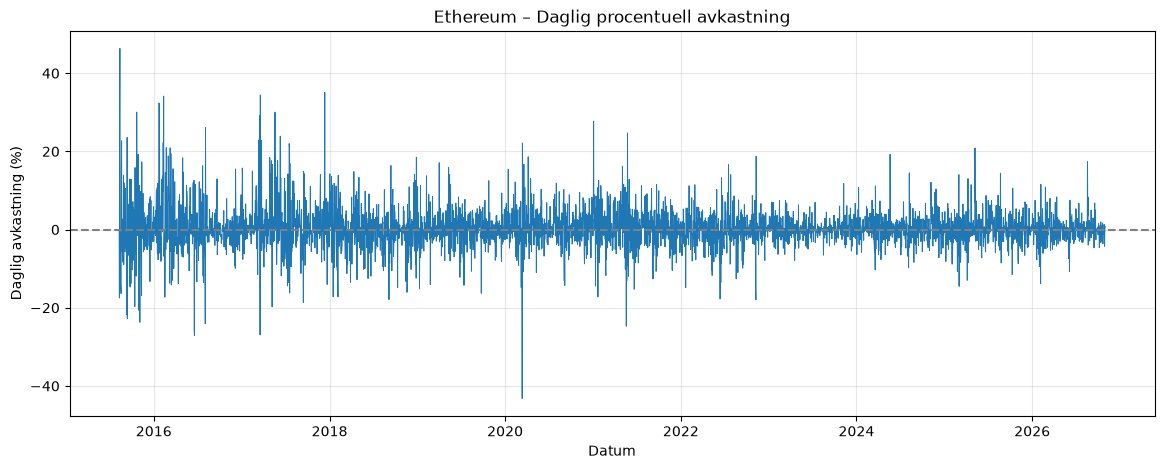

In [11]:

# Beräkna daglig procentuell avkastning
df["ETH_Return"] = df["ETH_Price"].pct_change() * 100

# Visa beskrivande statistik
display(df["ETH_Return"].describe())

# Visualisera daglig avkastning
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["ETH_Return"], linewidth=0.7)

plt.axhline(0, color="gray", linestyle="--")
plt.title("Ethereum – Daglig procentuell avkastning")
plt.xlabel("Datum")
plt.ylabel("Daglig avkastning (%)")
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Analysen omfattar 4 103 dagliga avkastningsobservationer.

- **Genomsnittlig daglig avkastning:** 0,32 %
- **Median:** 0,05 %
- **Standardavvikelse:** 5,31 %
- **Största uppgång:** +46,34 %
- **Största nedgång:** −43,20 %

Diagrammet visar att Ethereum har haft perioder med mycket kraftiga prisrörelser, särskilt under de tidiga åren. Volatiliteten verkar också variera över tid.

**Slutsats:** Ethereum uppvisar hög och varierande volatilitet. Skillnaden mellan medelvärde och median tyder på att extrema positiva avkastningar påverkar genomsnittet. Detta är viktigt att beakta vid statistisk analys och modellutvärdering.



###  Fördelning av daglig avkastning

Vi undersöker fördelningen av Ethereums dagliga procentuella avkastning med ett histogram.

Syftet är att förstå hur avkastningen fördelar sig, identifiera extrema värden och undersöka om fördelningen liknar en normalfördelning.

Detta är relevant för våra framtida statistiska analyser och modellutvärderingar.


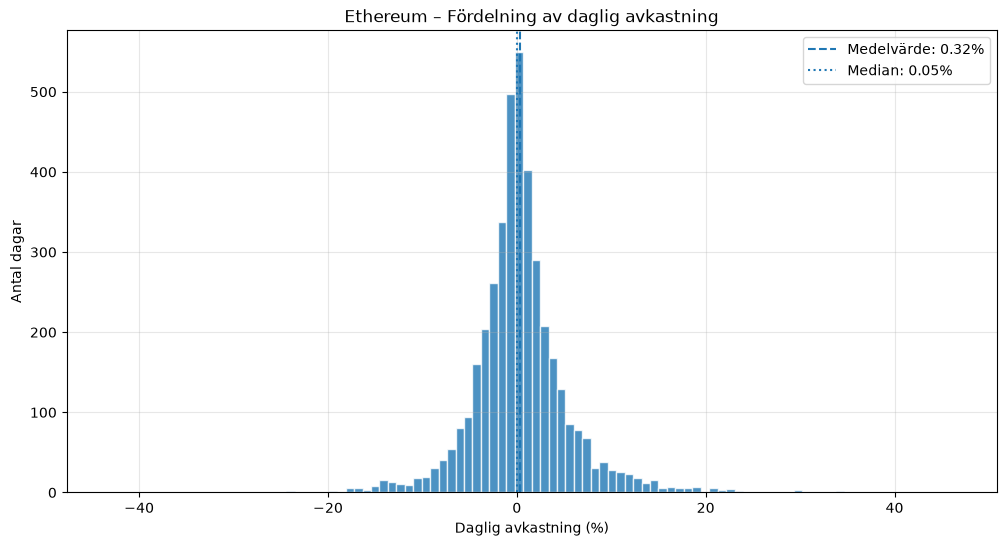

Skevhet (Skewness): 0.645
Toppighet (Kurtosis): 7.774


In [12]:

import numpy as np
import matplotlib.pyplot as plt

# Hämta daglig avkastning och uteslut första NaN-värdet
returns = df["ETH_Return"].dropna()

# Beräkna medelvärde och median
mean_return = returns.mean()
median_return = returns.median()

# Visualisera fördelningen
plt.figure(figsize=(12, 6))

plt.hist(
    returns,
    bins=100,
    edgecolor="white",
    alpha=0.8
)

# Markera medelvärde och median
plt.axvline(mean_return, linestyle="--",
            label=f"Medelvärde: {mean_return:.2f}%")

plt.axvline(median_return, linestyle=":",
            label=f"Median: {median_return:.2f}%")

plt.title("Ethereum – Fördelning av daglig avkastning")
plt.xlabel("Daglig avkastning (%)")
plt.ylabel("Antal dagar")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Undersök fördelningens form
print("Skevhet (Skewness):", round(returns.skew(), 3))
print("Toppighet (Kurtosis):", round(returns.kurt(), 3))



### Resultat och slutsats

Histogrammet visar fördelningen av Ethereums dagliga procentuella avkastning under perioden augusti 2015 – november 2026 (4 103 dagliga förändringar).

**Observationer:**
- De flesta dagliga prisförändringarna ligger nära 0 %.
- Fördelningen har en tydlig topp kring 0 %, men också långa svansar med extrema prisrörelser.
- **Medelvärde:** 0,32 % per dag.
- **Median:** 0,05 % per dag.
- **Skevhet (Skewness):** 0,645 – fördelningen är något högerskev.
- **Toppighet (Kurtosis):** 7,774 – fördelningen har betydligt tyngre svansar än en normalfördelning.

**Slutsats:** Ethereums dagliga avkastning är koncentrerad kring små förändringar, men extrema prisrörelser förekommer. Fördelningen avviker från normalfördelningen, vilket behöver beaktas vid statistiska analyser och riskbedömningar.



### Volatilitet över tid (Rolling Volatility)

Vi undersöker hur Ethereums volatilitet har förändrats historiskt genom att beräkna den rullande standardavvikelsen för daglig avkastning över 30 dagar.

Syftet är att identifiera perioder med hög respektive låg volatilitet och undersöka hur marknadens risknivå varierar över tid.


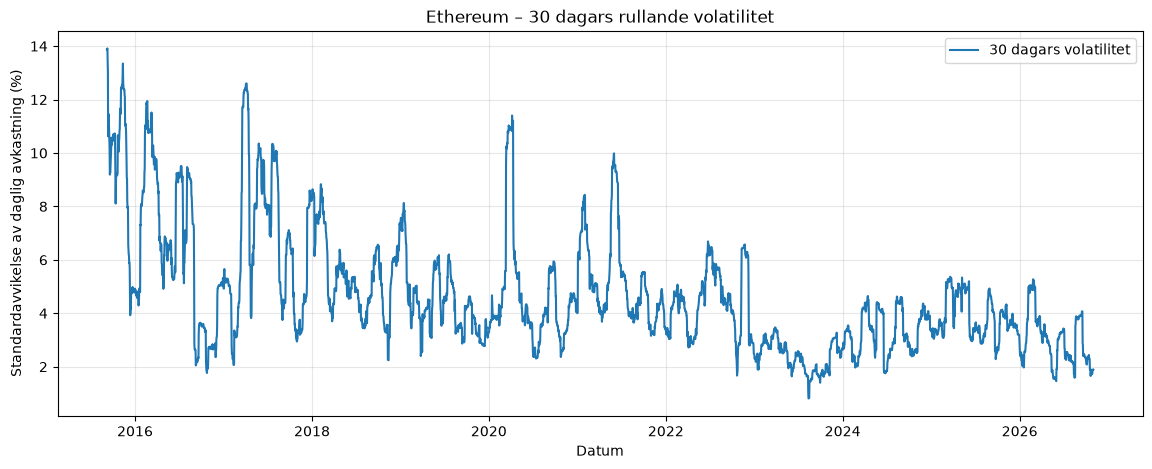

count    4074.000000
mean        4.670366
std         2.258149
min         0.812162
25%         3.140338
50%         4.151654
75%         5.430219
max        13.913605
Name: Volatility_30D, dtype: float64

In [13]:

# Beräkna 30 dagars rullande volatilitet
df["Volatility_30D"] = (
    df["ETH_Return"]
    .rolling(window=30, min_periods=30)
    .std()
)

# Visualisera volatiliteten över tid
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["Volatility_30D"],
    label="30 dagars volatilitet"
)

plt.title("Ethereum – 30 dagars rullande volatilitet")
plt.xlabel("Datum")
plt.ylabel("Standardavvikelse av daglig avkastning (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Sammanfattande statistik
display(df["Volatility_30D"].describe())



### Resultat och slutsats

Ethereums 30-dagars rullande volatilitet (Rolling Volatility) varierade mellan 0,81 % och 13,91 %, med ett genomsnitt på 4,67 %.

Volatiliteten var generellt högre under de tidiga åren, men flera tydliga toppar förekommer även senare.

**Slutsats:** Volatiliteten förändras över tid, vilket bör beaktas vid modellutvärdering och backtesting.



### Korrelation mellan Bitcoin och Ethereum

Vi undersöker sambandet mellan BTC:s och ETH:s dagliga procentuella avkastning med Pearsons korrelationskoefficient (Pearson Correlation).

Syftet är att förstå hur de två tillgångarnas prisförändringar samvarierar och om sambandet är relevant för vår fortsatta analys.


Pearson-korrelation mellan ETH och BTC: 0.599


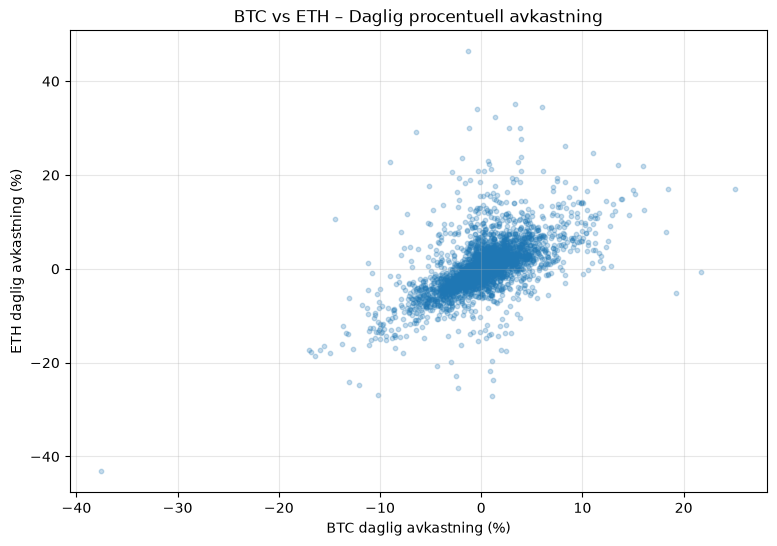

In [14]:

# Beräkna daglig procentuell avkastning för Bitcoin
df["BTC_Return"] = df["BTC_Price"].pct_change() * 100

# Beräkna korrelationen mellan ETH och BTC
correlation = df["ETH_Return"].corr(df["BTC_Return"])

print(f"Pearson-korrelation mellan ETH och BTC: {correlation:.3f}")

# Visualisera sambandet mellan dagliga avkastningar
plt.figure(figsize=(9, 6))

plt.scatter(
    df["BTC_Return"],
    df["ETH_Return"],
    alpha=0.25,
    s=10
)

plt.title("BTC vs ETH – Daglig procentuell avkastning")
plt.xlabel("BTC daglig avkastning (%)")
plt.ylabel("ETH daglig avkastning (%)")
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Pearsons korrelationskoefficient mellan ETH:s och BTC:s dagliga avkastning är **0,599**, vilket visar ett måttligt starkt positivt linjärt samband.

Diagrammet visar att tillgångarna ofta rör sig i samma riktning, men med betydande variationer och vissa extrema observationer.

**Slutsats:** Bitcoin och Ethereum uppvisar tydlig samvariation, men korrelationen innebär inte att Bitcoins prisrörelser orsakar Ethereums prisrörelser.


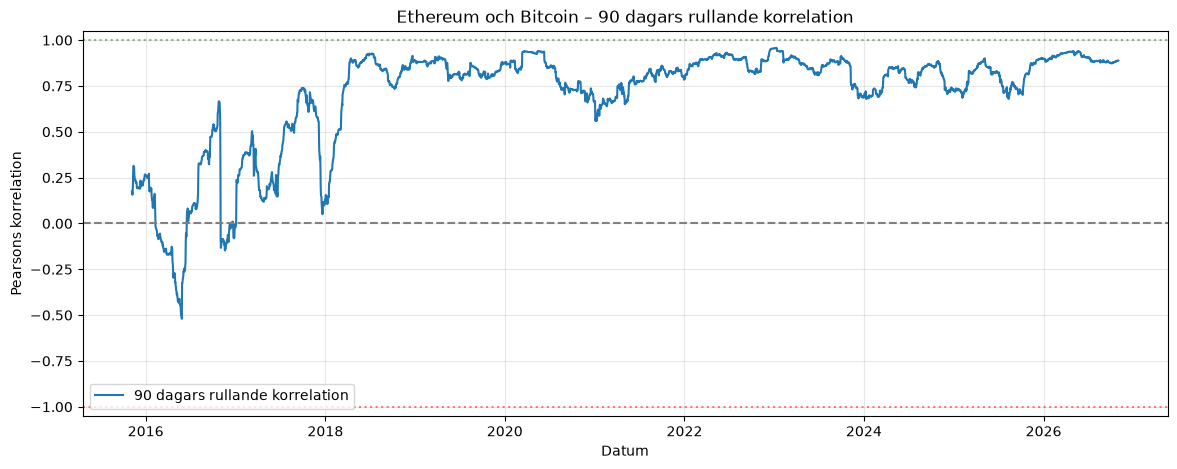

count    4014.000000
mean        0.705831
std         0.283335
min        -0.520113
25%         0.694696
50%         0.820821
75%         0.880891
max         0.957802
Name: Correlation_90D, dtype: float64

In [15]:

# Beräkna korrelationen för de senaste 90 dagarna
df["Correlation_90D"] = (
    df["ETH_Return"]
    .rolling(window=90, min_periods=90)
    .corr(df["BTC_Return"])
)

# Visualisera korrelationen över tid
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["Correlation_90D"],
    label="90 dagars rullande korrelation"
)

# Referenslinjer
plt.axhline(0, color="gray", linestyle="--")
plt.axhline(1, color="green", linestyle=":", alpha=0.5)
plt.axhline(-1, color="red", linestyle=":", alpha=0.5)

plt.title("Ethereum och Bitcoin – 90 dagars rullande korrelation")
plt.xlabel("Datum")
plt.ylabel("Pearsons korrelation")
plt.ylim(-1.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Sammanfattande statistik
display(df["Correlation_90D"].describe())



### Resultat och slutsats

Den 90-dagars rullande korrelationen (Rolling Correlation) varierade mellan **−0,52 och 0,96**, med ett genomsnitt på 0,71.

Sambandet var instabilt under 2015–2017, men har sedan 2018 huvudsakligen varit starkt positivt, ofta över 0,70.

**Slutsats:** Korrelationen mellan BTC och ETH förändras över tid. Detta visar att sambandet inte är konstant och kan vara relevant vid analys av olika marknadsperioder.




### Glidande medelvärden (Moving Averages)

Vi använder glidande medelvärden för att identifiera långsiktiga trender och minska effekten av kortsiktiga prisvariationer.

#### 200 dagars glidande medelvärde (SMA 200)

SMA 200 beräknar det genomsnittliga ETH-priset under de senaste 200 dagarna. Vi undersöker hur priset historiskt har förhållit sig till denna trendindikator.


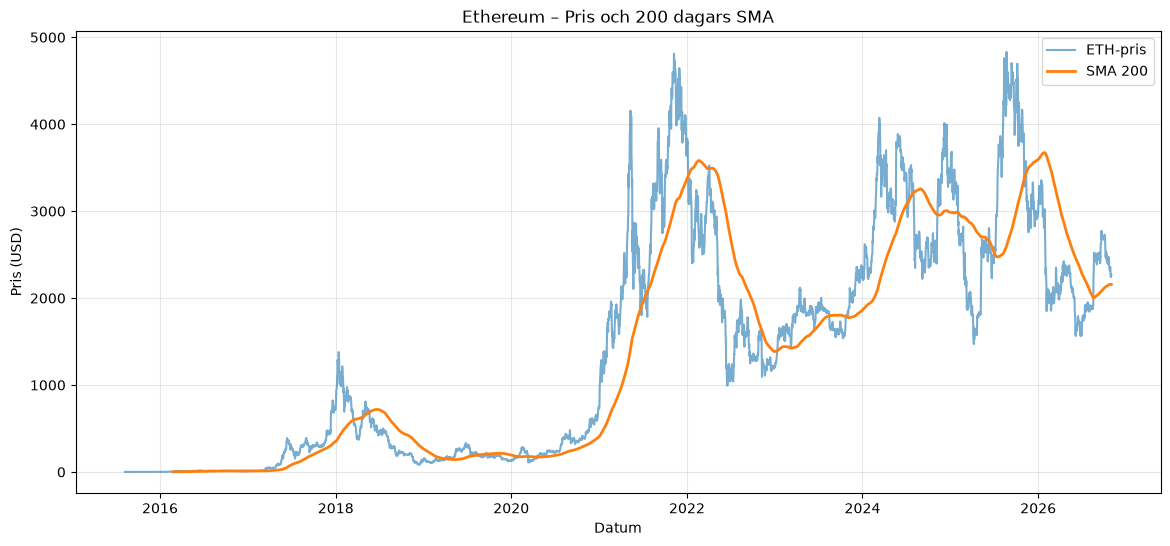

Saknade SMA 200-värden: 199


In [16]:

# Beräkna 200 dagars Simple Moving Average
df["SMA_200"] = (
    df["ETH_Price"]
    .rolling(window=200, min_periods=200)
    .mean()
)

# Visualisera ETH-priset och SMA 200
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["ETH_Price"],
    label="ETH-pris",
    alpha=0.6
)

plt.plot(
    df["Date"],
    df["SMA_200"],
    label="SMA 200",
    linewidth=2
)

plt.title("Ethereum – Pris och 200 dagars SMA")
plt.xlabel("Datum")
plt.ylabel("Pris (USD)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Kontrollera hur många värden som saknas
print("Saknade SMA 200-värden:", df["SMA_200"].isna().sum())



### Resultat och slutsats

SMA 200 visar Ethereums långsiktiga pristrend genom att jämna ut kortsiktiga prisvariationer.

ETH-priset har historiskt rört sig både över och under SMA 200. Indikatorn reagerar med viss fördröjning på kraftiga prisförändringar.

De första 199 observationerna saknar SMA-värden eftersom beräkningen kräver 200 dagars prishistorik.

**Slutsats:** SMA 200 är användbar som trendindikator och kan senare undersökas i relation till våra ackumulationszoner.



####  Bull Market Support Band (20W SMA + 21W EMA)

Vi beräknar Ethereums 20-veckors SMA och 21-veckors EMA för att undersöka långsiktiga marknadstrender.

Området mellan indikatorerna kallas Bull Market Support Band (BMSB) och används som ett kompletterande verktyg för att analysera historiska prisrörelser.


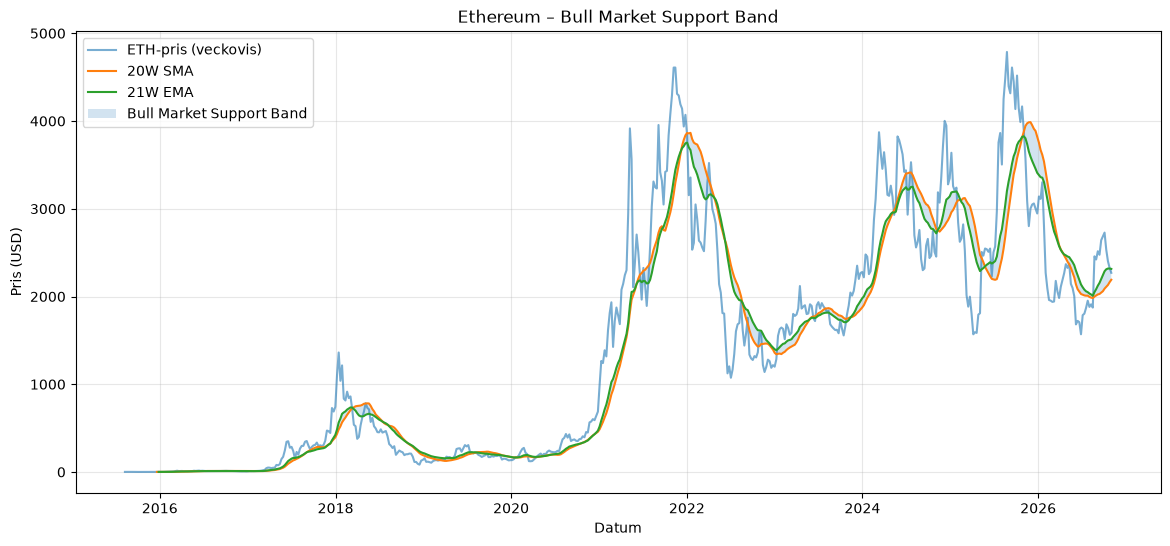

Antal veckor: 587
Saknade 20W SMA: 19
Saknade 21W EMA: 20


In [17]:

# Skapa veckodata med söndag som veckans sista dag
weekly = (
    df.set_index("Date")["ETH_Price"]
    .resample("W-SUN")
    .last()
    .to_frame(name="ETH_Price")
)

# Beräkna 20 veckors Simple Moving Average
weekly["SMA_20W"] = (
    weekly["ETH_Price"]
    .rolling(window=20, min_periods=20)
    .mean()
)

# Beräkna 21 veckors Exponential Moving Average
weekly["EMA_21W"] = (
    weekly["ETH_Price"]
    .ewm(span=21, adjust=False, min_periods=21)
    .mean()
)

# Visualisera pris och Bull Market Support Band
plt.figure(figsize=(14, 6))

plt.plot(
    weekly.index,
    weekly["ETH_Price"],
    label="ETH-pris (veckovis)",
    alpha=0.6
)

plt.plot(
    weekly.index,
    weekly["SMA_20W"],
    label="20W SMA",
    linewidth=1.5
)

plt.plot(
    weekly.index,
    weekly["EMA_21W"],
    label="21W EMA",
    linewidth=1.5
)

# Markera området mellan de två medelvärdena
plt.fill_between(
    weekly.index,
    weekly["SMA_20W"],
    weekly["EMA_21W"],
    alpha=0.2,
    label="Bull Market Support Band"
)

plt.title("Ethereum – Bull Market Support Band")
plt.xlabel("Datum")
plt.ylabel("Pris (USD)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Kontrollera omfattning och saknade värden
print("Antal veckor:", len(weekly))
print("Saknade 20W SMA:", weekly["SMA_20W"].isna().sum())
print("Saknade 21W EMA:", weekly["EMA_21W"].isna().sum())



### Resultat och slutsats

Analysen omfattar 587 veckor. De första 19 respektive 20 veckorna saknar SMA- och EMA-värden eftersom indikatorerna kräver tillräcklig prishistorik.

BMSB följer Ethereums långsiktiga prisutveckling och jämnar ut kortsiktiga svängningar. Priset har historiskt rört sig både över och under bandet.

**Slutsats:** BMSB är en användbar trendindikator som kan undersökas vidare i relation till våra regressionsbaserade ackumulationszoner.



####  BMSB med logaritmisk prisskala

Vi visualiserar ETH-priset tillsammans med 20W SMA och 21W EMA på en logaritmisk skala för att tydligare undersöka historiska trender och relativa prisförändringar.


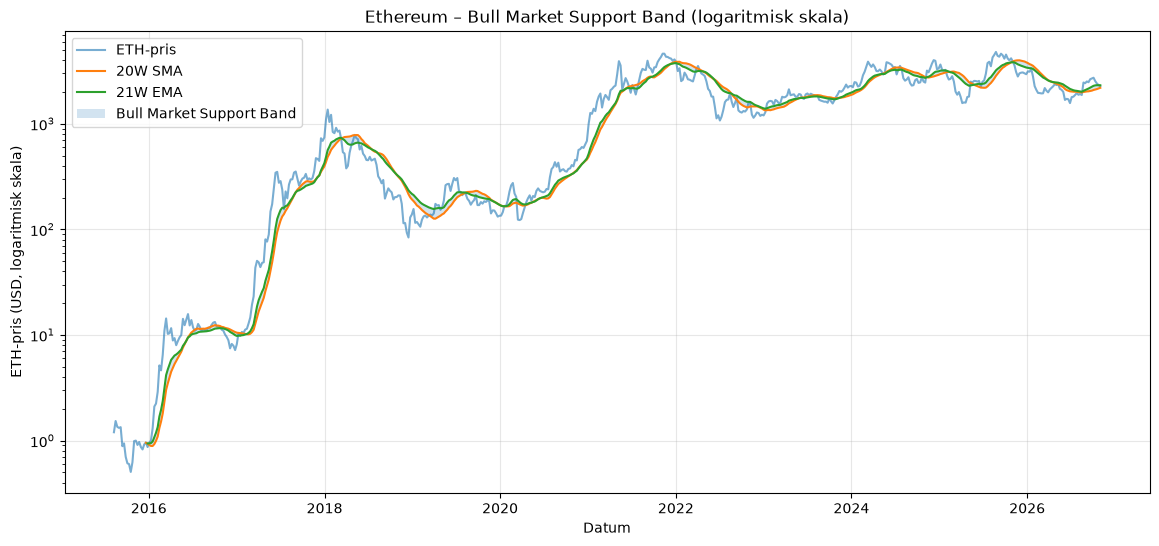

In [18]:

# Visualisera BMSB med logaritmisk prisskala
plt.figure(figsize=(14, 6))

# ETH:s veckovisa pris
plt.plot(
    weekly.index,
    weekly["ETH_Price"],
    label="ETH-pris",
    alpha=0.6
)

# Glidande medelvärden
plt.plot(weekly.index, weekly["SMA_20W"],
         label="20W SMA", linewidth=1.5)

plt.plot(weekly.index, weekly["EMA_21W"],
         label="21W EMA", linewidth=1.5)

# Markera området mellan indikatorerna
plt.fill_between(
    weekly.index,
    weekly["SMA_20W"],
    weekly["EMA_21W"],
    alpha=0.2,
    label="Bull Market Support Band"
)

# Använd logaritmisk Y-axel
plt.yscale("log")

plt.title("Ethereum – Bull Market Support Band (logaritmisk skala)")
plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Den logaritmiska skalan tydliggör BMSB:s utveckling under hela perioden 2015–2026, särskilt under Ethereums tidiga år.

ETH-priset har växlat mellan att ligga över och under bandet. Både 20W SMA och 21W EMA följer den långsiktiga trenden med viss eftersläpning.

**Slutsats:** Logaritmisk visualisering ger en tydligare bild av BMSB:s historiska beteende, men visar inte i sig om indikatorn har något prediktivt värde.



#### ETH-prisets position relativt BMSB

Vi klassificerar ETH:s veckovisa pris utifrån om det ligger över, inom eller under Bull Market Support Band.

Syftet är att undersöka hur ofta respektive marknadsläge har förekommit historiskt.


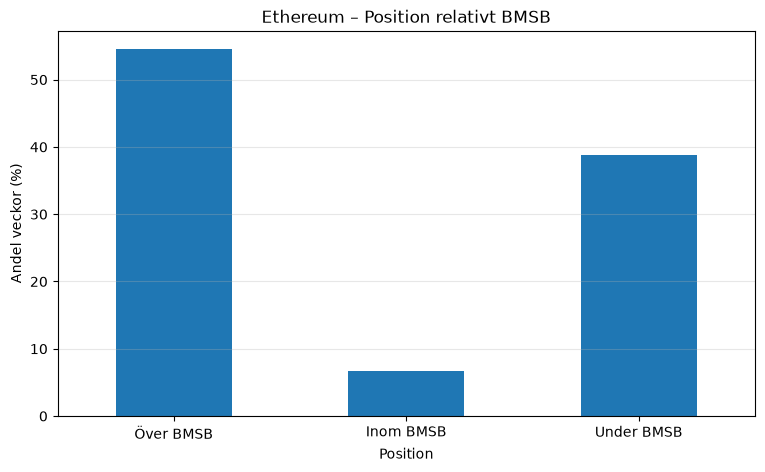

Antal analyserade veckor: 567


Position
Över BMSB     54.5
Inom BMSB      6.7
Under BMSB    38.8
Name: proportion, dtype: float64

In [19]:

import numpy as np

# Använd endast veckor där båda indikatorerna finns
bmsb = weekly.dropna(subset=["SMA_20W", "EMA_21W"]).copy()

# Identifiera bandets övre och nedre gräns
bmsb["Upper_Band"] = bmsb[["SMA_20W", "EMA_21W"]].max(axis=1)
bmsb["Lower_Band"] = bmsb[["SMA_20W", "EMA_21W"]].min(axis=1)

# Klassificera ETH-prisets position relativt bandet
conditions = [
    bmsb["ETH_Price"] > bmsb["Upper_Band"],
    bmsb["ETH_Price"] < bmsb["Lower_Band"]
]

bmsb["Position"] = np.select(
    conditions,
    ["Över BMSB", "Under BMSB"],
    default="Inom BMSB"
)

# Beräkna andelen veckor i varje kategori
order = ["Över BMSB", "Inom BMSB", "Under BMSB"]

distribution = (
    bmsb["Position"]
    .value_counts(normalize=True)
    .reindex(order, fill_value=0)
    * 100
)

# Visualisera fördelningen
plt.figure(figsize=(9, 5))
distribution.plot(kind="bar")

plt.title("Ethereum – Position relativt BMSB")
plt.xlabel("Position")
plt.ylabel("Andel veckor (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Antal analyserade veckor:", len(bmsb))
display(distribution.round(2))



### Resultat och slutsats

Av 567 analyserade veckor låg ETH-priset:
- **54,5 %** över BMSB.
- **6,7 %** inom BMSB.
- **38,8 %** under BMSB.

**Slutsats:** ETH har oftast handlats över BMSB, medan priset relativt sällan befunnit sig inom bandet. BMSB fungerar främst som en trendindikator snarare än ett brett ackumulationsområde.



####  BMSB – Årlig fördelning

Vi undersöker hur ofta Ethereum har handlats över, inom och under BMSB under respektive år.

Syftet är att identifiera skillnader mellan marknadsperioder och förstå hur ETH:s position relativt BMSB förändras över tid.


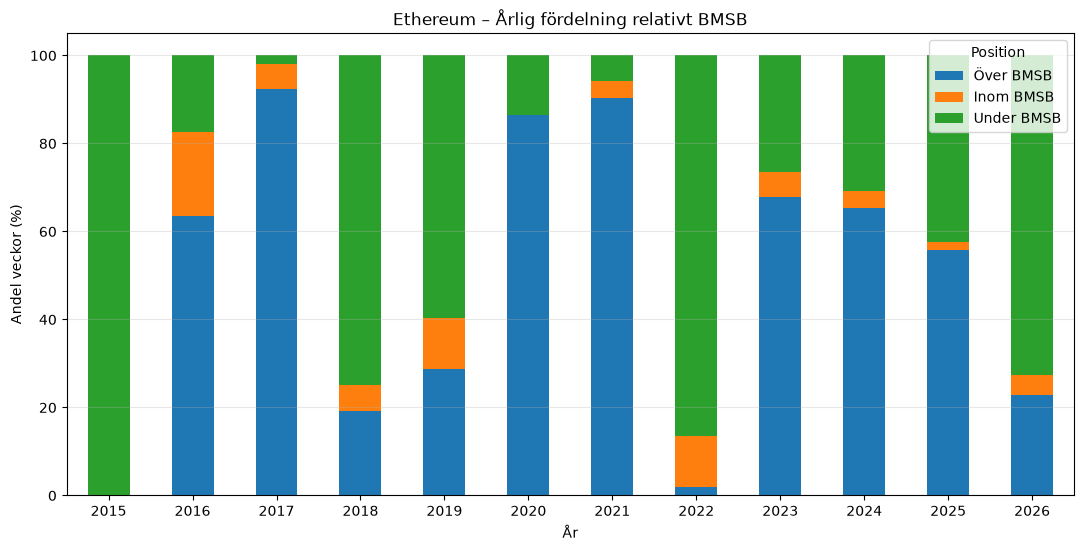

Position,Över BMSB,Inom BMSB,Under BMSB
Year,,,
2015,0.0,0.0,100.0
2016,63.5,19.2,17.3
2017,92.5,5.7,1.9
2018,19.2,5.8,75.0
2019,28.8,11.5,59.6
2020,86.5,0.0,13.5
2021,90.4,3.8,5.8
2022,1.9,11.5,86.5
2023,67.9,5.7,26.4


In [20]:

# Skapa årtal från veckodatans datum
bmsb["Year"] = bmsb.index.year

# Beräkna procentuell fördelning av BMSB-position per år
yearly_distribution = pd.crosstab(
    bmsb["Year"],
    bmsb["Position"],
    normalize="index"
) * 100

# Bestäm ordningen på kategorierna
yearly_distribution = yearly_distribution.reindex(
    columns=["Över BMSB", "Inom BMSB", "Under BMSB"],
    fill_value=0
)

# Visualisera fördelningen per år
yearly_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Ethereum – Årlig fördelning relativt BMSB")
plt.xlabel("År")
plt.ylabel("Andel veckor (%)")
plt.legend(title="Position")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

# Visa fördelningen i tabell
display(yearly_distribution.round(1))



### Resultat och slutsats

ETH:s position relativt BMSB varierar kraftigt mellan åren.

- **2017 och 2021:** ETH låg över BMSB under mer än 90 % av veckorna.
- **2018 och 2022:** ETH låg under BMSB under 75 % respektive 86,5 % av veckorna.
- **2026:** ETH låg under BMSB under 72,7 % av de analyserade veckorna.

**Slutsats:** BMSB speglar tydliga skillnader mellan historiska marknadsperioder och kan vara användbar för att klassificera långsiktiga trender.



###  ETH/BTC-förhållandet (Relative Strength)

Vi analyserar prisförhållandet mellan Ethereum och Bitcoin för att undersöka hur ETH:s relativa marknadsstyrka har förändrats över tid.

Ett stigande ETH/BTC-förhållande innebär att Ethereum utvecklas starkare än Bitcoin, medan ett sjunkande förhållande innebär motsatsen.


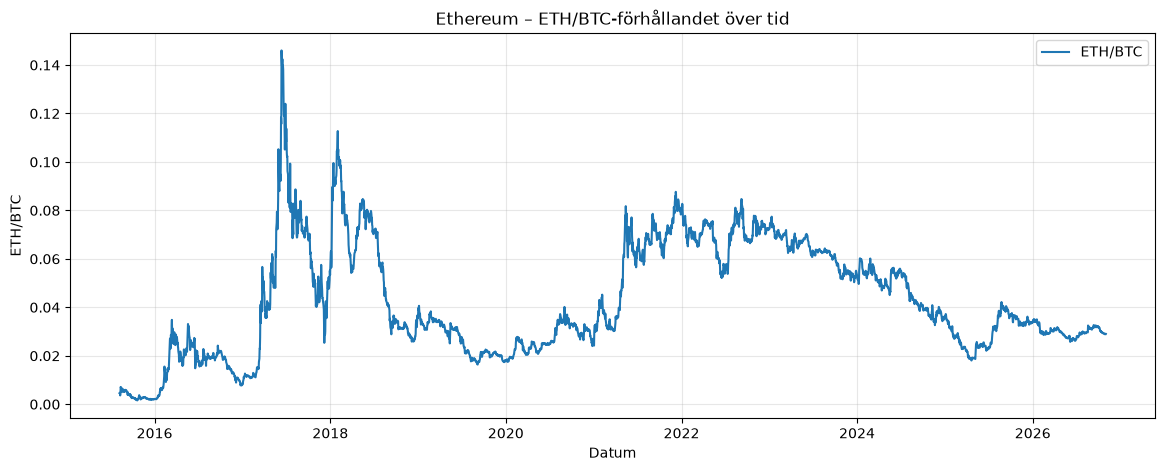

count    4104.000000
mean        0.042726
std         0.023175
min         0.001567
25%         0.025594
50%         0.035246
75%         0.063014
max         0.146015
Name: ETH_BTC_Ratio, dtype: float64

In [21]:

# Beräkna ETH/BTC-förhållandet
df["ETH_BTC_Ratio"] = df["ETH_Price"] / df["BTC_Price"]

# Visualisera ETH:s relativa utveckling mot Bitcoin
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["ETH_BTC_Ratio"],
    label="ETH/BTC"
)

plt.title("Ethereum – ETH/BTC-förhållandet över tid")
plt.xlabel("Datum")
plt.ylabel("ETH/BTC")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Sammanfattande statistik
display(df["ETH_BTC_Ratio"].describe())



### Resultat och slutsats

ETH/BTC-förhållandet varierade mellan **0,0016 och 0,1460**, med ett genomsnitt på 0,0427.

Ethereum stärktes kraftigt relativt Bitcoin under 2017 och 2021, medan förhållandet generellt försvagades under 2023–2025.

**Slutsats:** Ethereums relativa styrka mot Bitcoin förändras betydligt mellan olika marknadsperioder, vilket gör ETH/BTC-förhållandet relevant som kompletterande indikator i vår analys.



### Logaritmisk transformation (Log Transformation)

Vi transformerar ETH-priset med den naturliga logaritmen (Natural Logarithm) för att undersöka långsiktiga tillväxtmönster.

Syftet är att bedöma om logaritmerade priser är lämpliga för vår kommande regressionsmodell.


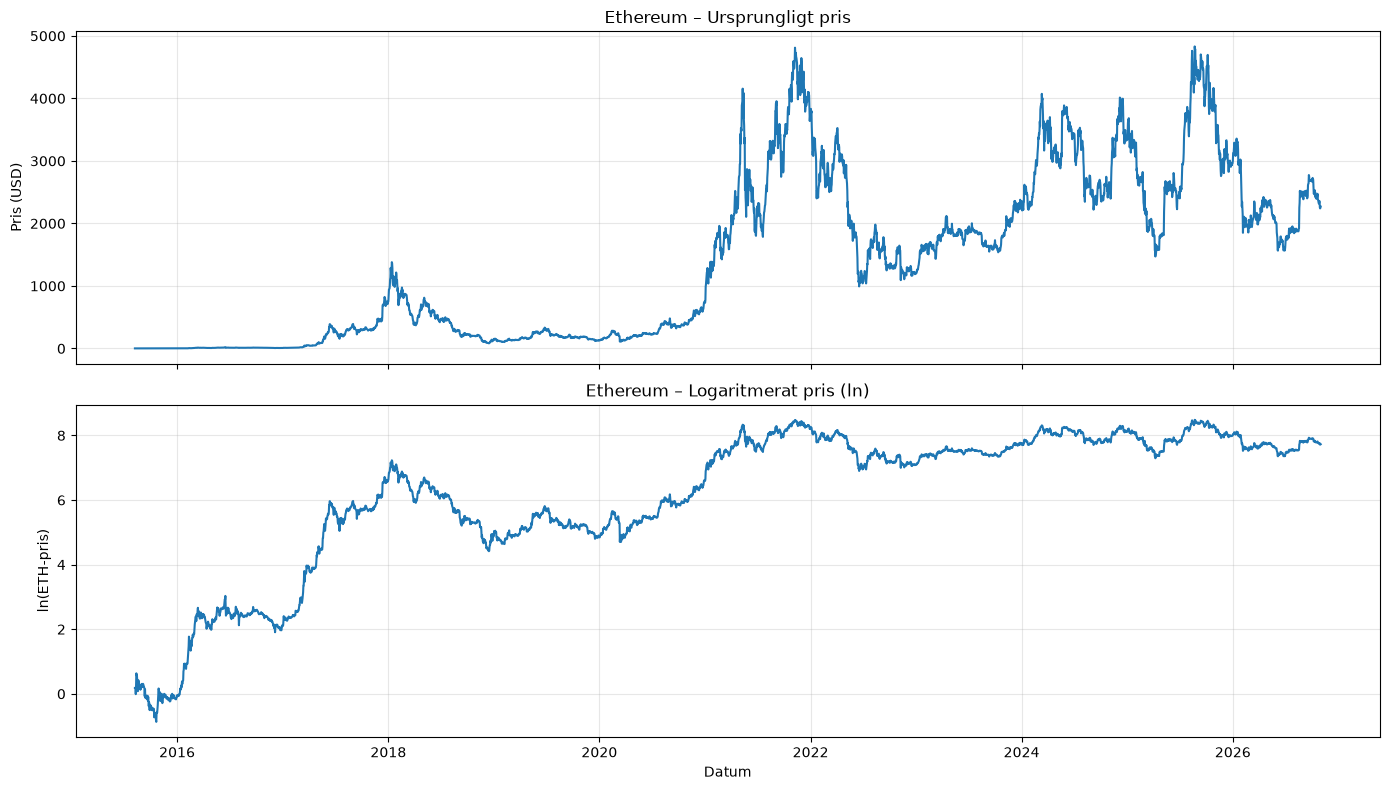

count    4104.000000
mean        6.133881
std         2.186820
min        -0.867501
25%         5.228262
50%         7.120400
75%         7.789546
max         8.482830
Name: Log_ETH_Price, dtype: float64

In [22]:

# Beräkna den naturliga logaritmen av ETH-priset
df["Log_ETH_Price"] = np.log(df["ETH_Price"])

# Jämför originalpris och logaritmerat pris
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Ursprungligt ETH-pris
axes[0].plot(df["Date"], df["ETH_Price"])
axes[0].set_title("Ethereum – Ursprungligt pris")
axes[0].set_ylabel("Pris (USD)")
axes[0].grid(alpha=0.3)

# Logaritmerat ETH-pris
axes[1].plot(df["Date"], df["Log_ETH_Price"])
axes[1].set_title("Ethereum – Logaritmerat pris (ln)")
axes[1].set_xlabel("Datum")
axes[1].set_ylabel("ln(ETH-pris)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Visa beskrivande statistik för logaritmerat pris
display(df["Log_ETH_Price"].describe())


#
### Resultat och slutsats

Den logaritmiska transformationen gör Ethereums långsiktiga prisutveckling tydligare genom att minska skillnaderna mellan höga och låga prisnivåer.

Den relativa tillväxten verkar ha avtagit över tid, samtidigt som betydande prisvariationer kvarstår.

**Slutsats:** Logaritmerat pris är en relevant kandidat för vår regressionsmodell. Modellens lämplighet behöver dock utvärderas genom träning och residualanalys.



### Samband mellan logaritmerad tid och pris

Vi undersöker sambandet mellan logaritmerad tid och logaritmerat ETH-pris för att bedöma om en logaritmisk regressionsmodell är lämplig.

Vi letar efter långsiktiga tillväxtmönster, avvikelser och möjliga förändringar i trenden.


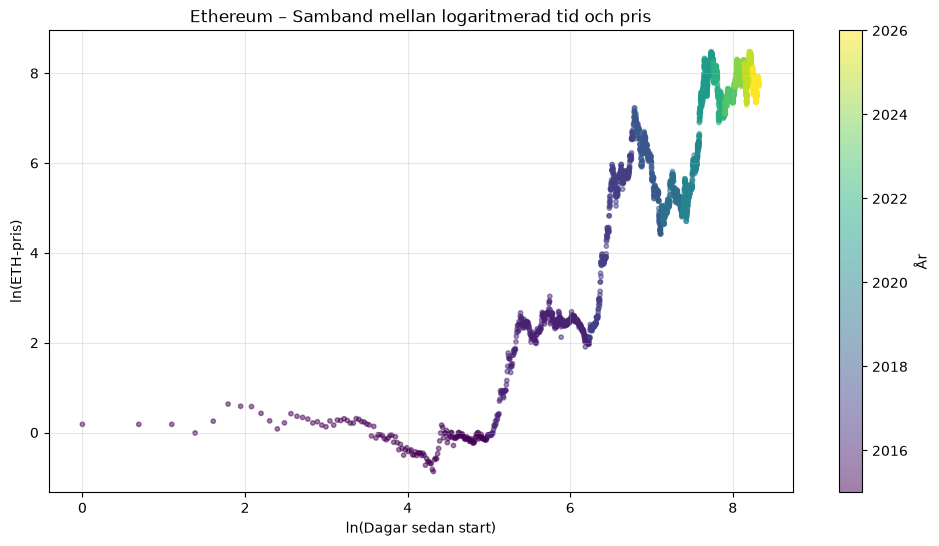

In [23]:

# Beräkna antal dagar sedan första observationen
# Vi börjar på dag 1 eftersom log(0) inte är definierad
df["Days_Since_Start"] = (
    df["Date"] - df["Date"].min()
).dt.days + 1

# Logaritmera tiden
df["Log_Time"] = np.log(df["Days_Since_Start"])

# Visualisera sambandet mellan logaritmerad tid och pris
plt.figure(figsize=(12, 6))

plt.scatter(
    df["Log_Time"],
    df["Log_ETH_Price"],
    c=df["Date"].dt.year,
    cmap="viridis",
    s=10,
    alpha=0.5
)

plt.colorbar(label="År")
plt.title("Ethereum – Samband mellan logaritmerad tid och pris")
plt.xlabel("ln(Dagar sedan start)")
plt.ylabel("ln(ETH-pris)")
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Sambandet mellan logaritmerad tid och logaritmerat ETH-pris är positivt men inte tydligt linjärt.

Stora variationer och förändringar i tillväxtmönstret förekommer mellan olika marknadsperioder.

**Slutsats:** En log-log-regression är värd att undersöka, men det är osäkert om en enda regressionskurva kan beskriva hela Ethereums prishistorik tillräckligt väl.



### Extrema prisrörelser (Outlier Analysis)

Vi identifierar de största dagliga prisförändringarna och undersöker hur ofta ETH har rört sig minst 10 % under en dag.

Syftet är att upptäcka extrema marknadsperioder som kan påverka vår regressionsmodell och dess utvärdering.


,Date,ETH_Return,Abs_Return
5,2015-08-13 00:00:00+00:00,46.335404,46.335404
1678,2020-03-12 00:00:00+00:00,-43.198894,43.198894
857,2017-12-12 00:00:00+00:00,35.068951,35.068951
589,2017-03-19 00:00:00+00:00,34.432565,34.432565
187,2016-02-11 00:00:00+00:00,34.133525,34.133525
168,2016-01-23 00:00:00+00:00,32.384904,32.384904
4,2015-08-12 00:00:00+00:00,30.101010,30.101010
75,2015-10-22 00:00:00+00:00,30.043694,30.043694
650,2017-05-19 00:00:00+00:00,30.023094,30.023094
586,2017-03-16 00:00:00+00:00,29.139005,29.139005


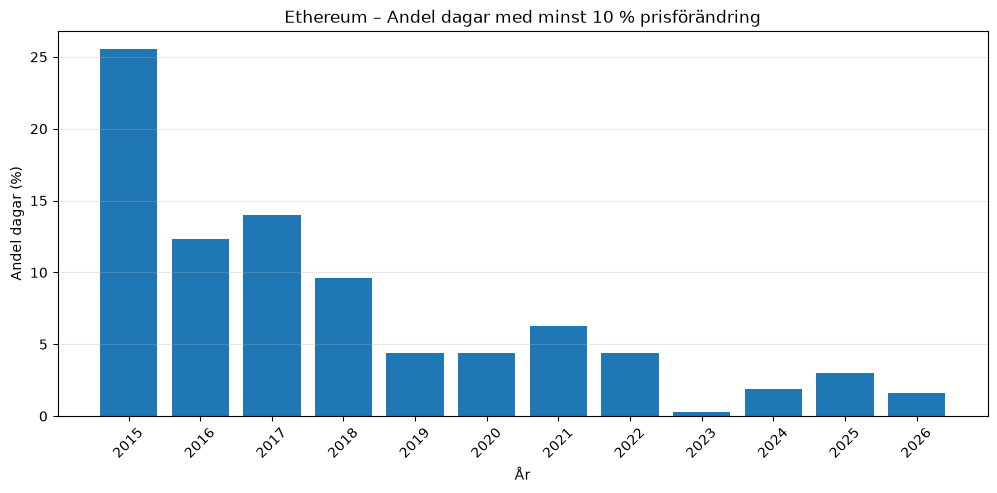

Date
2015    25.52
2016    12.30
2017    13.97
2018     9.59
2019     4.38
2020     4.37
2021     6.30
2022     4.38
2023     0.27
2024     1.91
2025     3.01
2026     1.64
Name: Extreme_Day, dtype: float64

In [24]:

# Förbered daglig avkastning
extremes = df.dropna(subset=["ETH_Return"]).copy()

# Beräkna absolut daglig avkastning
extremes["Abs_Return"] = extremes["ETH_Return"].abs()

# Visa de 10 största dagliga prisrörelserna
top10 = extremes.nlargest(10, "Abs_Return")

display(top10[["Date", "ETH_Return", "Abs_Return"]])

# Identifiera dagar med minst 10 % prisförändring
extremes["Extreme_Day"] = extremes["Abs_Return"] >= 10

# Beräkna andelen extrema dagar per år
yearly_extremes = (
    extremes.groupby(extremes["Date"].dt.year)["Extreme_Day"]
    .mean() * 100
)

# Visualisera andelen extrema dagar
plt.figure(figsize=(12, 5))

plt.bar(yearly_extremes.index, yearly_extremes.values)

plt.title("Ethereum – Andel dagar med minst 10 % prisförändring")
plt.xlabel("År")
plt.ylabel("Andel dagar (%)")
plt.xticks(yearly_extremes.index, rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

display(yearly_extremes.round(2))



### Resultat och slutsats

Andelen dagar med prisförändringar på minst ±10 % har generellt minskat över tid.

- **2015:** 25,52 % av dagarna.
- **2017:** 13,97 %.
- **2023:** Endast 0,27 %.
- **2025:** 3,01 %.

**Slutsats:** Extrema dagliga prisrörelser har blivit mindre vanliga, men förekommer fortfarande. Detta bör beaktas vid modellutvärdering, särskilt eftersom marknadsförhållandena förändras över tid.



### Sammanfattning av EDA

EDA visar att Ethereum har genomgått stora prisförändringar och flera marknadscykler, med varierande volatilitet över tid.

**Viktigaste slutsatserna:**
- Logaritmerat pris är relevant för vår regressionsanalys.
- Sambandet mellan logaritmerad tid och pris är inte tydligt linjärt.
- Volatilitet och extrema prisrörelser varierar mellan marknadsperioder.
- SMA 200 och BMSB ger kompletterande information om långsiktiga trender.

**Inför ML:** Vi behöver testa modellens stabilitet, analysera residualer och använda kronologisk validering för att undvika Data Leakage.


In [25]:
 
# Kontrollera variablerna inför regression
model_columns = ["Log_Time", "Log_ETH_Price"]

print("Saknade värden:")
print(df[model_columns].isna().sum())

print("\nOgiltiga numeriska värden:")
print((~np.isfinite(df[model_columns])).sum())

print("\nDatum i kronologisk ordning:",
      df["Date"].is_monotonic_increasing)

print("Antal observationer:", len(df))


Saknade värden:
Log_Time         0
Log_ETH_Price    0
dtype: int64

Ogiltiga numeriska värden:
Log_Time         0
Log_ETH_Price    0
dtype: int64

Datum i kronologisk ordning: True
Antal observationer: 4104



## Regression & Machine Learning

### Förberedelse av ML-data

Vi förbereder logaritmerad tid (X) och logaritmerat ETH-pris (y) för vår första regressionsmodell.

Vi behåller datum och originalpris för att senare kunna utvärdera modellen och tolka resultaten i USD.


In [26]:

# Skapa ett separat dataset för regressionsanalysen
model_df = df[
    ["Date", "Days_Since_Start", "Log_Time",
     "Log_ETH_Price", "ETH_Price"]
].copy()

# Definiera modellens input (X) och target (y)
X = model_df[["Log_Time"]]
y = model_df["Log_ETH_Price"]

# Kontrollera datasetets struktur
print("Antal observationer:", len(model_df))
print("X shape:", X.shape)
print("y shape:", y.shape)

# Visa första observationerna
display(model_df.head())


Antal observationer: 4104
X shape: (4104, 1)
y shape: (4104,)


,Date,Days_Since_Start,Log_Time,Log_ETH_Price,ETH_Price
0,2015-08-08 00:00:00+00:00,1,0.000000,0.182313,1.19999
1,2015-08-09 00:00:00+00:00,2,0.693147,0.182313,1.19999
2,2015-08-10 00:00:00+00:00,3,1.098612,0.182313,1.19999
3,2015-08-11 00:00:00+00:00,4,1.386294,-0.010050,0.99000
4,2015-08-12 00:00:00+00:00,5,1.609438,0.253091,1.28800



### Resultat och slutsats

Datasetet innehåller 4 104 observationer med logaritmerad tid (X) och logaritmerat ETH-pris (y).

Variablerna har kontrollerats och innehåller inga saknade eller ogiltiga värden.

**Slutsats:** Datan är förberedd för kronologisk uppdelning och efterföljande modellträning.



### Kronologisk uppdelning (Train / Validation / Test Split)

Vi delar upp datasetet kronologiskt enligt gruppens gemensamma tidsperioder.

Syftet är att träna modellen på äldre observationer och utvärdera dess förmåga att generalisera till senare perioder utan dataläckage (Data Leakage).


In [27]:

# Säkerställ korrekt datumformat
model_df["Date"] = pd.to_datetime(model_df["Date"], utc=True)

# Träningsdata: 2015–2022
train_df = model_df[
    model_df["Date"] < "2023-01-01"
].copy()

# Valideringsdata: 2023–2024
val_df = model_df[
    (model_df["Date"] >= "2023-01-01") &
    (model_df["Date"] < "2025-01-01")
].copy()

# Testdata: 2025–oktober 2026
test_df = model_df[
    (model_df["Date"] >= "2025-01-01") &
    (model_df["Date"] < "2026-11-01")
].copy()

# Kontrollera antal observationer och datum
for name, dataset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(dataset)} observationer")
    print("Period:", dataset["Date"].min().date(),
          "till", dataset["Date"].max().date())

# Kontrollera att perioderna inte överlappar
assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

print("\nKronologisk uppdelning godkänd!")



Train: 2703 observationer
Period: 2015-08-08 till 2022-12-31

Validation: 731 observationer
Period: 2023-01-01 till 2024-12-31

Test: 669 observationer
Period: 2025-01-01 till 2026-10-31

Kronologisk uppdelning godkänd!



### Resultat och slutsats

Datasetet har delats upp kronologiskt i Train (2015–2022), Validation (2023–2024) och Test (2025–2026).

**Slutsats:** Uppdelningen säkerställer att modellen tränas på äldre observationer och utvärderas på senare perioder.



### Träning av logaritmisk regression

Vi tränar en linjär regressionsmodell (Linear Regression) med logaritmerad tid som förklarande variabel och logaritmerat ETH-pris som målvariabel.

Syftet är att skapa en första långsiktig trendmodell som senare kan utvärderas på osedd data.


Intercept: -8.5289
Koefficient: 1.9989


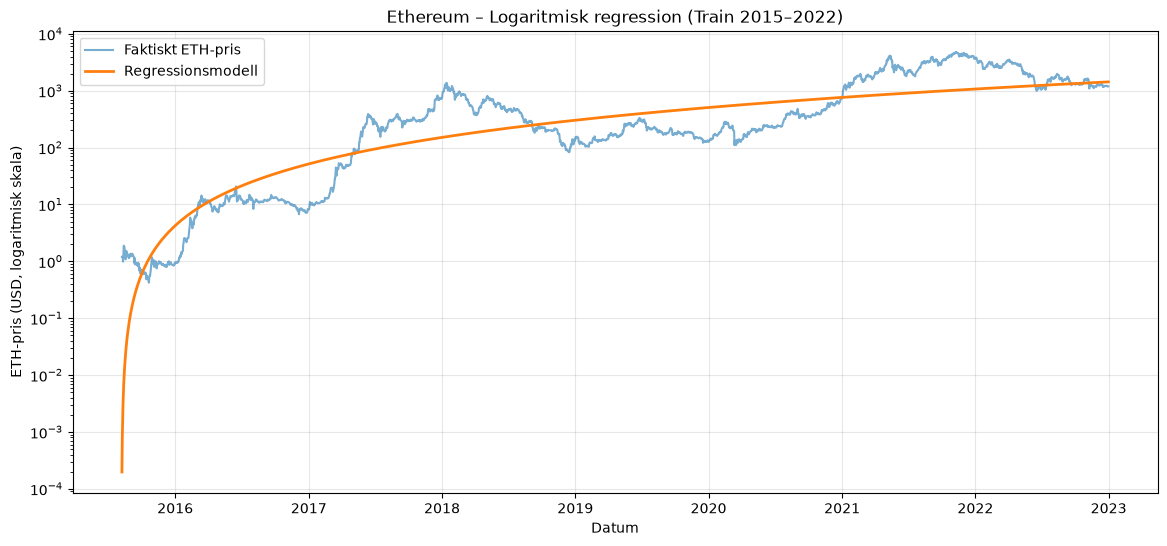

In [28]:

from sklearn.linear_model import LinearRegression

# Definiera X och y från träningsperioden
X_train = train_df[["Log_Time"]]
y_train = train_df["Log_ETH_Price"]

# Skapa och träna regressionsmodellen
model = LinearRegression()
model.fit(X_train, y_train)

# Beräkna modellens förutsägelser på träningsdata
train_pred_log = model.predict(X_train)

# Omvandla förutsägelserna tillbaka till USD
train_pred_usd = np.exp(train_pred_log)

# Visa modellens parametrar
print("Intercept:", round(model.intercept_, 4))
print("Koefficient:", round(model.coef_[0], 4))

# Visualisera faktisk och modellerad prisutveckling
plt.figure(figsize=(14, 6))

plt.plot(
    train_df["Date"],
    train_df["ETH_Price"],
    label="Faktiskt ETH-pris",
    alpha=0.6
)

plt.plot(
    train_df["Date"],
    train_pred_usd,
    label="Regressionsmodell",
    linewidth=2
)

plt.yscale("log")

plt.title("Ethereum – Logaritmisk regression (Train 2015–2022)")
plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Den logaritmiska regressionsmodellen tränades på ETH-priser från 2015–2022 och visar en långsiktigt stigande trend med avtagande tillväxttakt.

Modellen uppvisar dock betydande avvikelser från de faktiska priserna, särskilt under tidiga observationer och större marknadscykler.

**Slutsats:** Modellen fångar en övergripande tillväxttrend men beskriver inte alla marknadsperioder väl. Residualanalys och utvärdering på osedd data behövs innan vi kan bedöma modellens tillförlitlighet.



### Residualanalys (Residual Analysis)

Vi undersöker skillnaden mellan faktiska och modellerade logaritmerade ETH-priser, så kallade residualer.

Syftet är att identifiera systematiska avvikelsers och bedöma om vår första regressionsmodell beskriver den långsiktiga prisutvecklingen tillräckligt väl.


Cowen-form: P(t) = 10^(0.8681 * ln(t) - 3.7041)
MAE (log): 0.8719
RMSE (log): 1.0463


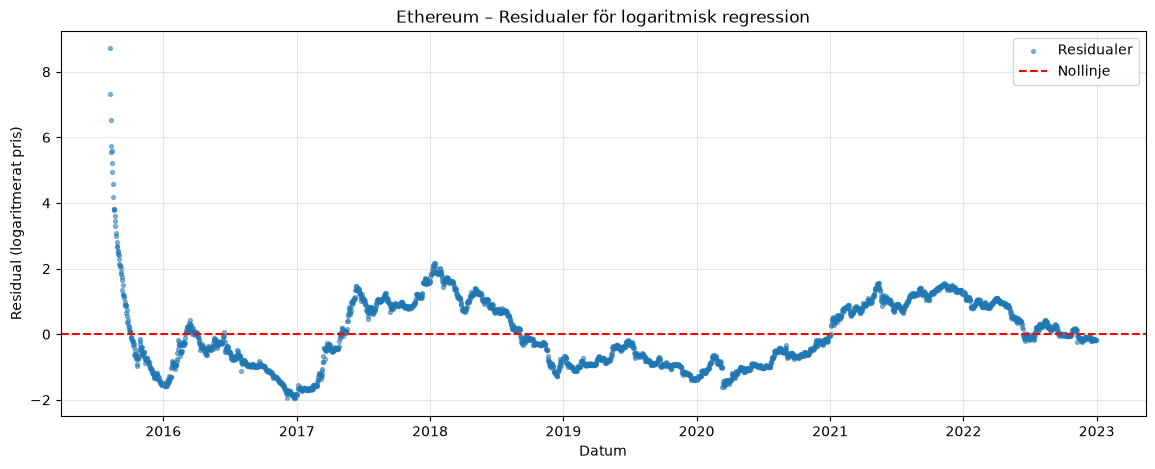

In [29]:

# Skriv modellen i Cowens ekvationsform
a = model.coef_[0] / np.log(10)
b = -model.intercept_ / np.log(10)

print(f"Cowen-form: P(t) = 10^({a:.4f} * ln(t) - {b:.4f})")

# Skapa dataset för residualanalys
train_results = train_df[["Date", "Log_ETH_Price"]].copy()

# Beräkna modellens förutsägelser
train_results["Pred_Log"] = model.predict(X_train)

# Residual = faktiskt värde minus förutsagt värde
train_results["Residual"] = (
    train_results["Log_ETH_Price"] -
    train_results["Pred_Log"]
)

# Beräkna modellfel på träningsdata
mae = train_results["Residual"].abs().mean()
rmse = np.sqrt((train_results["Residual"] ** 2).mean())

print(f"MAE (log): {mae:.4f}")
print(f"RMSE (log): {rmse:.4f}")

# Visualisera residualerna över tid
plt.figure(figsize=(14, 5))

plt.scatter(
    train_results["Date"],
    train_results["Residual"],
    s=8,
    alpha=0.5,
    label="Residualer"
)

plt.axhline(0, color="red", linestyle="--", label="Nollinje")

plt.title("Ethereum – Residualer för logaritmisk regression")
plt.xlabel("Datum")
plt.ylabel("Residual (logaritmerat pris)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Residualanalysen visar betydande och systematiska avvikelser mellan faktiska och modellerade ETH-priser.

- **MAE (log):** 0,8719
- **RMSE (log):** 1,0463

Residualerna uppvisar tydliga mönster över tid, med särskilt stora avvikelser under de tidigaste observationerna.

**Slutsats:** Den första regressionsmodellen har begränsningar som behöver undersökas innan vi konstruerar regressionsband.



### Kvantilregression – Nedre prisband (Quantile Regression)

Vi tränar två kvantilregressionsmodeller på ETH-priser från 2015–2022 för att uppskatta den 10:e och 25:e percentilen av den logaritmerade prisfördelningen.

Syftet är att skapa ett första regressionsbaserat ackumulationsband inspirerat av Benjamin Cowens metod för historiskt låga prisområden.


Antal korsningar mellan kvantilkurvorna: 0


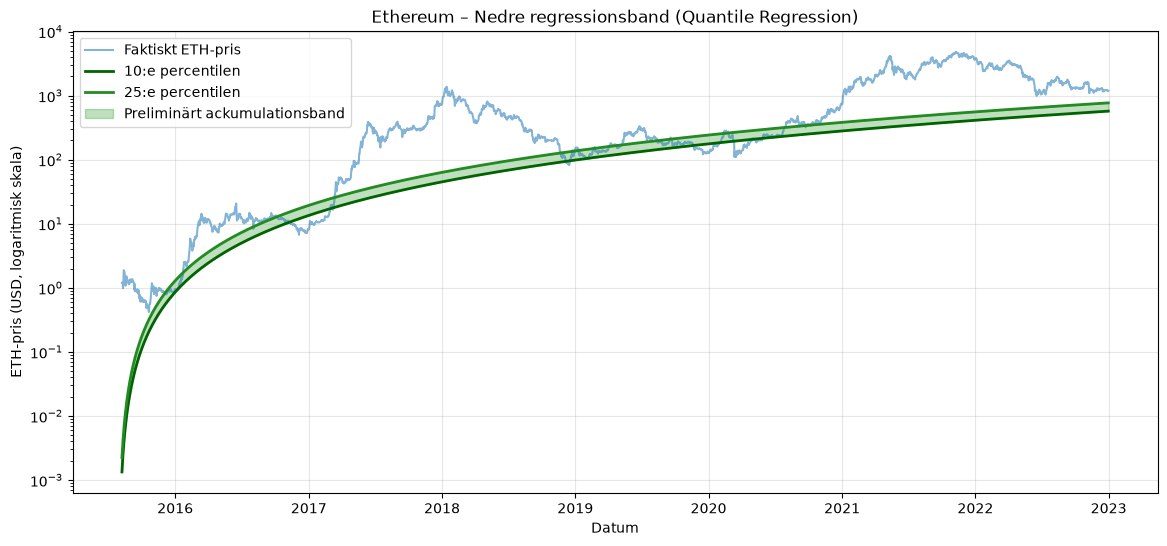

In [30]:

from sklearn.linear_model import QuantileRegressor

# Utgå från samma träningsperiod som tidigare
quantile_train = train_df.copy()

# Definiera tid från Ethereums lansering
launch_date = pd.Timestamp("2015-07-30", tz="UTC")

quantile_train["Days_Since_Launch"] = (
    quantile_train["Date"] - launch_date
).dt.days

# Logaritmera tidsvariabeln
quantile_train["Log_Time_Launch"] = np.log(
    quantile_train["Days_Since_Launch"]
)

# Definiera träningsvariabler
X_quantile = quantile_train[["Log_Time_Launch"]]
y_quantile = quantile_train["Log_ETH_Price"]

# Träna modeller för den 10:e och 25:e percentilen
q10_model = QuantileRegressor(
    quantile=0.10, alpha=0, solver="highs"
)

q25_model = QuantileRegressor(
    quantile=0.25, alpha=0, solver="highs"
)

q10_model.fit(X_quantile, y_quantile)
q25_model.fit(X_quantile, y_quantile)

# Förutsägelser omvandlade från logaritmerat pris till USD
quantile_train["Q10"] = np.exp(
    q10_model.predict(X_quantile)
)

quantile_train["Q25"] = np.exp(
    q25_model.predict(X_quantile)
)

# Kontrollera att nedre gränsen inte överstiger den övre
crossings = (
    quantile_train["Q10"] > quantile_train["Q25"]
).sum()

print("Antal korsningar mellan kvantilkurvorna:", crossings)

# Visualisera de första ackumulationsbanden
plt.figure(figsize=(14, 6))

plt.plot(
    quantile_train["Date"],
    quantile_train["ETH_Price"],
    label="Faktiskt ETH-pris",
    alpha=0.55
)

plt.plot(
    quantile_train["Date"],
    quantile_train["Q10"],
    color="darkgreen",
    label="10:e percentilen",
    linewidth=2
)

plt.plot(
    quantile_train["Date"],
    quantile_train["Q25"],
    color="forestgreen",
    label="25:e percentilen",
    linewidth=2
)

# Markera området mellan kvantilkurvorna
if crossings == 0:
    plt.fill_between(
        quantile_train["Date"],
        quantile_train["Q10"],
        quantile_train["Q25"],
        color="green",
        alpha=0.25,
        label="Preliminärt ackumulationsband"
    )
else:
    print("VARNING: Kvantilkurvorna korsar varandra.")

plt.yscale("log")
plt.title("Ethereum – Nedre regressionsband (Quantile Regression)")
plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### Resultat och slutsats

Kvantilregression med Q10 och Q25 skapade ett sammanhängande nedre prisband utan korsningar.

Bandet följer en långsiktig tillväxtkurva men uppvisar betydande avvikelser från vissa historiska bottennivåer, särskilt under de tidigaste åren.

**Slutsats:** Kvantilregression är en lovande metod för att identifiera nedre prisområden, men bandens kvalitet och stabilitet behöver utvärderas innan de kan användas som ackumulationszoner.



### 5.9 Jämförelse av regressionsmodeller

Vi jämför vår befintliga log-log-kvantilregression med en andragradspolynomisk kvantilregression (Polynomial Quantile Regression).

Syftet är att undersöka om en mer flexibel kurva kan beskriva lägre historiska ETH-prisnivåer bättre, utan att förlora förmågan att generalisera till osedd data.



### Sammanfattning av tidigare experiment

Vi testade Polynomial Quantile Regression med tre band samt olika tidsförskjutningar. Resultaten visade problem med korsande kurvor och instabil prestanda vid Walk-Forward Validation.

Därför går vi vidare med en Cowen-inspirerad modell med gemensam kurvatur och separata kvantilnivåer.



### Cowen-inspirerad Quantile Regression – Shared Curvature

Vi bygger tre nedre regressionskurvor (Q1, Q10 och Q25) med gemensam kvadratisk kurvatur.

Modellen använder logaritmerad tid sedan Ethereums lansering som förklarande variabel och logaritmerat ETH-pris som beroende variabel.

Vi tränar på 2015–2022 och utvärderar på 2023–2024. Eventuella korsningar hanteras med Quantile Rearrangement.


Träning – korsningsobservationer före sortering: 19
Validering – korsningsobservationer före sortering: 0

Gemensam kurvatur: 0.16467


,Period,Kvantil,Pinball Loss,Coverage (%)
0,Träning,Q1,0.0066,0.9619
1,Träning,Q10,0.0543,10.0259
2,Träning,Q25,0.1142,24.9723
3,Validering,Q1,0.0039,0.0000
4,Validering,Q10,0.0182,0.0000
5,Validering,Q25,0.0241,25.8550


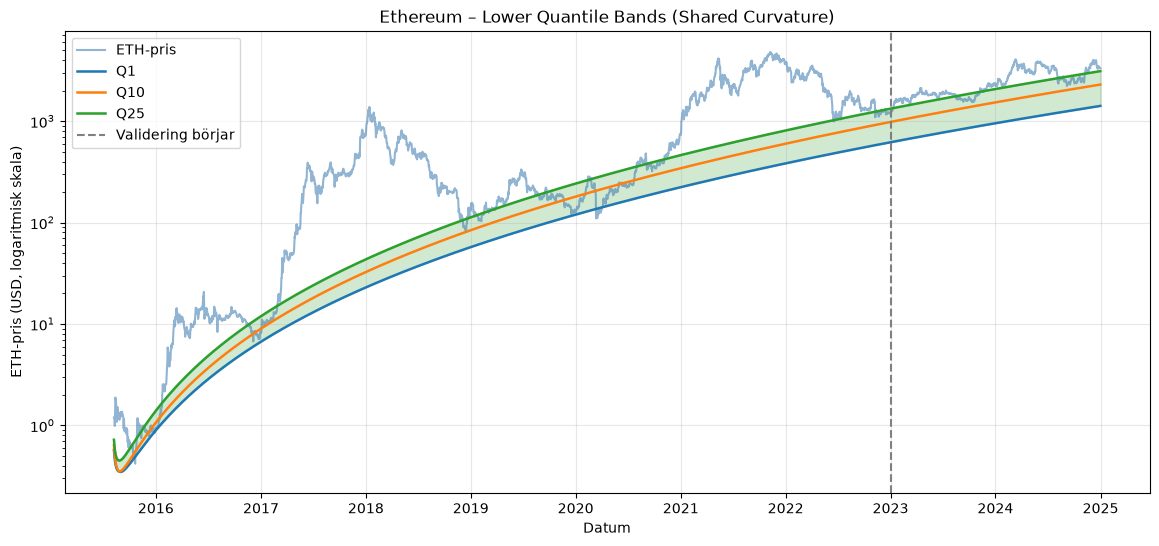

In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linprog
from scipy.sparse import csr_matrix, eye, hstack
from sklearn.metrics import mean_pinball_loss

# 1. Förbered tränings- och valideringsdata
cowen_train = train_df.sort_values("Date").copy()
cowen_val = val_df.sort_values("Date").copy()

eth_launch = pd.Timestamp("2015-07-30", tz="UTC")

def log_time(data):
    days = (data["Date"] - eth_launch).dt.days.to_numpy()
    assert np.all(days > 0), "Tiden måste vara större än noll."
    return np.log(days)

# Centrera tiden med enbart träningsdata
time_center = log_time(cowen_train).mean()

x = log_time(cowen_train) - time_center
y = np.log10(cowen_train["ETH_Price"].to_numpy())

# Cowens tre nedre kvantiler
levels = np.array([0.01, 0.10, 0.25])
names = ["Q1", "Q10", "Q25"]

n = len(y)
k = len(levels)
m = n * k

# 2. Bygg en gemensam modell:
# Varje kvantil får eget intercept och lutning,
# men samtliga delar samma kvadratiska koefficient.

design = np.zeros((m, 2 * k + 1))

for j in range(k):
    rows = slice(j * n, (j + 1) * n)
    design[rows, 2 * j] = 1
    design[rows, 2 * j + 1] = x

design[:, -1] = np.tile(x**2, k)

# 3. Minimera gemensam Pinball Loss
# med linjär optimering (HiGHS).

A_eq = hstack([
    csr_matrix(design),
    eye(m, format="csr"),
    -eye(m, format="csr")
], format="csr")

objective = np.r_[
    np.zeros(2 * k + 1),
    np.repeat(levels, n),
    np.repeat(1 - levels, n)
]

bounds = (
    [(None, None)] * (2 * k + 1)
    + [(0, None)] * (2 * m)
)

result = linprog(
    objective,
    A_eq=A_eq,
    b_eq=np.tile(y, k),
    bounds=bounds,
    method="highs"
)

if not result.success:
    raise RuntimeError(result.message)

coefficients = result.x[:2 * k + 1]
shared_curvature = coefficients[-1]

# 4. Funktion för att skapa bandprognoser
def predict_cowen(data):
    x_new = log_time(data) - time_center

    raw = np.column_stack([
        coefficients[2*j]
        + coefficients[2*j + 1] * x_new
        + shared_curvature * x_new**2
        for j in range(k)
    ])

    # Quantile Rearrangement:
    # sortera kurvorna vid varje datum
    return raw, np.sort(raw, axis=1)

# 5. Utvärdera på träning och validering
evaluation = []

for period, data in [
    ("Träning", cowen_train),
    ("Validering", cowen_val)
]:
    raw, predictions = predict_cowen(data)
    actual = np.log10(data["ETH_Price"].to_numpy())

    crossings = np.sum(
        np.any(np.diff(raw, axis=1) < 0, axis=1)
    )

    print(f"{period} – korsningsobservationer före sortering: {crossings}")

    for j, (name, q) in enumerate(zip(names, levels)):
        evaluation.append({
            "Period": period,
            "Kvantil": name,
            "Pinball Loss": mean_pinball_loss(
                actual, predictions[:, j], alpha=q
            ),
            "Coverage (%)": np.mean(
                actual < predictions[:, j]
            ) * 100
        })

print("\nGemensam kurvatur:", round(shared_curvature, 5))
display(pd.DataFrame(evaluation).round(4))

# 6. Visualisera band och ETH-pris
plot_df = pd.concat(
    [cowen_train, cowen_val]
).sort_values("Date").copy()

_, log_bands = predict_cowen(plot_df)
price_bands = 10 ** log_bands

plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["Date"],
    plot_df["ETH_Price"],
    color="steelblue",
    alpha=0.6,
    label="ETH-pris"
)

for j, name in enumerate(names):
    plt.plot(
        plot_df["Date"],
        price_bands[:, j],
        linewidth=1.8,
        label=name
    )

plt.fill_between(
    plot_df["Date"],
    price_bands[:, 0],
    price_bands[:, 2],
    color="green",
    alpha=0.18
)

plt.axvline(
    cowen_val["Date"].min(),
    linestyle="--",
    color="gray",
    label="Validering börjar"
)

plt.yscale("log")
plt.title("Ethereum – Lower Quantile Bands (Shared Curvature)")
plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Resultat och slutsats

Modellen med gemensam kurvatur (0,16467) skapade tre tydliga regressionskurvor för Q1, Q10 och Q25.

Träningsperiodens kvantiltäckning låg nära de förväntade nivåerna. Under valideringen uppnådde Q25 en täckning på 25,86 %, medan Q1 och Q10 låg på 0 %.

19 korsningsobservationer identifierades i träningsperioden före Quantile Rearrangement.

**Slutsats:** Modellen visar lovande resultat, men behöver ytterligare Walk-Forward Validation innan den kan användas för historisk backtesting.



### Walk-Forward Validation – Shared Curvature

Vi utvärderar vår Cowen-inspirerade Quantile Regression med Expanding Window under 2018–2022.

För varje år tränas modellen enbart på tidigare historik. Vi undersöker Pinball Loss, kvantiltäckning och korsningar mellan Q1, Q10 och Q25.

Syftet är att bedöma modellens stabilitet och förmåga att generalisera till osedd data.


Walk-Forward Validation per år:


,År,Kvantil,Pinball Loss,Coverage (%)
0,2018,Q1,0.0305,11.7808
1,2018,Q10,0.0844,12.6027
2,2018,Q25,0.1884,40.0000
3,2019,Q1,0.0341,33.4247
4,2019,Q10,0.0993,77.5342
5,2019,Q25,0.3271,100.0000
6,2020,Q1,0.0059,7.3770
7,2020,Q10,0.0514,47.5410
8,2020,Q25,0.0767,64.7541
9,2021,Q1,0.0104,0.0000



Genomsnitt per kvantil:


,Pinball Loss,Coverage (%)
Kvantil,,
Q1,0.0174,10.5165
Q10,0.0738,27.5356
Q25,0.1738,40.9508



Korsningar före Quantile Rearrangement:


,År,Korsningar
0,2018,239
1,2019,0
2,2020,0
3,2021,0
4,2022,0


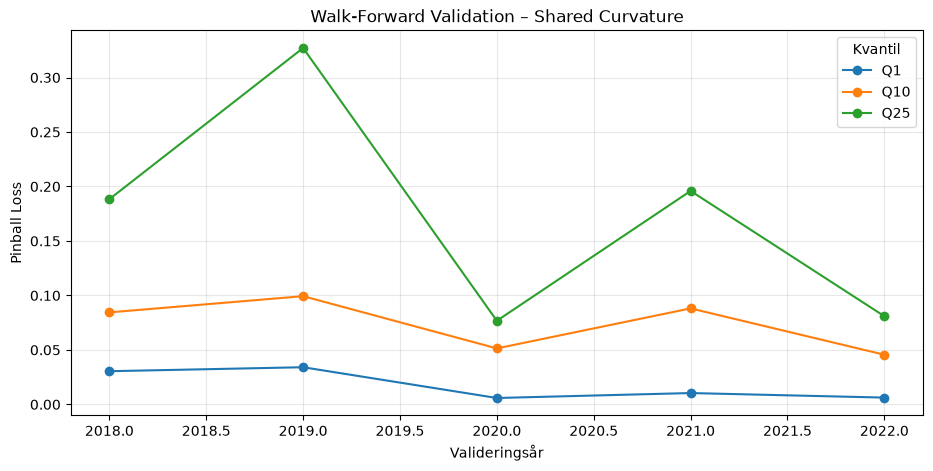

In [32]:

# 1. Funktion för att träna modellen på valfri historisk period
def fit_shared_curvature(data):

    days = (data["Date"] - eth_launch).dt.days.to_numpy()
    log_t = np.log(days)
    center = log_t.mean()

    x = log_t - center
    y = np.log10(data["ETH_Price"].to_numpy())

    n = len(y)
    k = len(levels)
    m = n * k

    # Gemensam kurvatur, separata intercept och lutningar
    design = np.zeros((m, 2 * k + 1))

    for j in range(k):
        rows = slice(j * n, (j + 1) * n)
        design[rows, 2*j] = 1
        design[rows, 2*j + 1] = x

    design[:, -1] = np.tile(x**2, k)

    # Gemensam optimering med Pinball Loss
    A_eq = hstack([
        csr_matrix(design),
        eye(m, format="csr"),
        -eye(m, format="csr")
    ], format="csr")

    objective = np.r_[
        np.zeros(2*k + 1),
        np.repeat(levels, n),
        np.repeat(1-levels, n)
    ]

    bounds = (
        [(None, None)] * (2*k + 1)
        + [(0, None)] * (2*m)
    )

    result = linprog(
        objective,
        A_eq=A_eq,
        b_eq=np.tile(y, k),
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x[:2*k + 1], center


# 2. Funktion för att förutsäga kvantilkurvor
def predict_shared_curvature(data, coefficients, center):

    days = (data["Date"] - eth_launch).dt.days.to_numpy()
    x = np.log(days) - center

    raw = np.column_stack([
        coefficients[2*j]
        + coefficients[2*j + 1] * x
        + coefficients[-1] * x**2
        for j in range(len(levels))
    ])

    # Quantile Rearrangement
    return raw, np.sort(raw, axis=1)


# 3. Walk-Forward Validation
wf_results = []
wf_crossings = []

for year in range(2018, 2023):

    # Endast tidigare år får användas vid träning
    train_fold = cowen_train[
        cowen_train["Date"].dt.year < year
    ].copy()

    val_fold = cowen_train[
        cowen_train["Date"].dt.year == year
    ].copy()

    # Träna om modellen för varje år
    coefficients, center = fit_shared_curvature(train_fold)

    raw, predictions = predict_shared_curvature(
        val_fold, coefficients, center
    )

    actual = np.log10(val_fold["ETH_Price"].to_numpy())

    # Kontrollera korsningar före Quantile Rearrangement
    crossings = np.sum(
        np.any(np.diff(raw, axis=1) < 0, axis=1)
    )

    wf_crossings.append({
        "År": year,
        "Korsningar": int(crossings)
    })

    # Utvärdera varje kvantil
    for j, (name, q) in enumerate(zip(names, levels)):

        wf_results.append({
            "År": year,
            "Kvantil": name,
            "Pinball Loss": mean_pinball_loss(
                actual,
                predictions[:, j],
                alpha=q
            ),
            "Coverage (%)": np.mean(
                actual < predictions[:, j]
            ) * 100
        })


# 4. Visa resultat
wf_cowen_df = pd.DataFrame(wf_results)

print("Walk-Forward Validation per år:")
display(wf_cowen_df.round(4))

print("\nGenomsnitt per kvantil:")
display(
    wf_cowen_df.groupby("Kvantil")[
        ["Pinball Loss", "Coverage (%)"]
    ].mean().round(4)
)

print("\nKorsningar före Quantile Rearrangement:")
display(pd.DataFrame(wf_crossings))

# 5. Visualisera modellens fel över tid
loss_table = wf_cowen_df.pivot(
    index="År",
    columns="Kvantil",
    values="Pinball Loss"
)[names]

loss_table.plot(marker="o", figsize=(11, 5))

plt.title("Walk-Forward Validation – Shared Curvature")
plt.xlabel("Valideringsår")
plt.ylabel("Pinball Loss")
plt.grid(alpha=0.3)
plt.show()



### Resultat och slutsats

Walk-Forward Validation (2018–2022) visar varierande prestanda mellan åren.

Den genomsnittliga kvantiltäckningen överstiger de förväntade nivåerna för Q1, Q10 och Q25. Under 2018 identifierades dessutom 239 korsningsobservationer före Quantile Rearrangement.

**Slutsats:** Modellen fungerar bättre under vissa perioder, men uppvisar bristande stabilitet. Ytterligare jämförelse med enklare modeller krävs innan slutligt modellval.



### Model Validation – 2023–2024

Vi jämför Log-Log, Polynomial Degree 2 och Shared Curvature Quantile Regression på valideringsperioden 2023–2024.

Alla modeller tränas på 2015–2022 och utvärderas med samma kvantilnivåer och log10-transformerat ETH-pris.

Vi undersöker Pinball Loss, Coverage och korsningar för att välja huvudmodell inför slutlig testning.


Sammanfattning – 2023–2024:


,Modell,Kvantil,Pinball Loss,Coverage (%)
6,Log-Log,Q1,0.0062,0.0000
7,Log-Log,Q10,0.0483,0.0000
8,Log-Log,Q25,0.0891,0.0000
15,Polynomial Degree 2,Q1,0.0044,0.0000
16,Polynomial Degree 2,Q10,0.0188,0.0000
17,Polynomial Degree 2,Q25,0.0242,26.2654
24,Shared Curvature,Q1,0.0039,0.0000
25,Shared Curvature,Q10,0.0182,0.0000
26,Shared Curvature,Q25,0.0241,25.8550



Korsningar före Quantile Rearrangement:


Period,2023,2024,Totalt
Modell,,,
Log-Log,0,0,0
Polynomial Degree 2,0,0,0
Shared Curvature,0,0,0


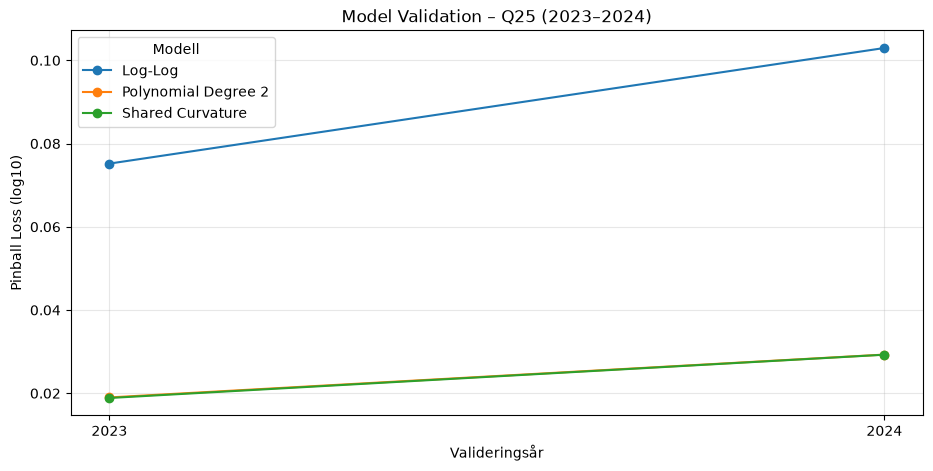

In [33]:

from sklearn.linear_model import QuantileRegressor
from sklearn.metrics import mean_pinball_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Förbered tränings- och valideringsdata
train = cowen_train.sort_values("Date").copy()
val = cowen_val.sort_values("Date").copy()

log_train = np.log(
    (train["Date"] - eth_launch).dt.days.to_numpy()
)
log_val = np.log(
    (val["Date"] - eth_launch).dt.days.to_numpy()
)

# Centrera enbart utifrån träningsdata
center = log_train.mean()

x_train = log_train - center
x_val = log_val - center

y_train = np.log10(train["ETH_Price"].to_numpy())
y_val = np.log10(val["ETH_Price"].to_numpy())

# 2. Skapa features för linjär och polynomisk regression
X_linear_train = x_train.reshape(-1, 1)
X_linear_val = x_val.reshape(-1, 1)

X_poly_train = np.column_stack([x_train, x_train**2])
X_poly_val = np.column_stack([x_val, x_val**2])

# 3. Träna Log-Log och Polynomial Degree 2
raw_predictions = {}

for model_name, X_tr, X_va in [
    ("Log-Log", X_linear_train, X_linear_val),
    ("Polynomial Degree 2", X_poly_train, X_poly_val)
]:
    predictions = []

    for q in levels:
        model = QuantileRegressor(
            quantile=q,
            alpha=0,
            solver="highs"
        )

        model.fit(X_tr, y_train)
        predictions.append(model.predict(X_va))

    raw_predictions[model_name] = np.column_stack(predictions)

# 4. Träna Shared Curvature på hela träningsperioden
shared_coefficients, shared_center = fit_shared_curvature(train)

shared_raw, _ = predict_shared_curvature(
    val, shared_coefficients, shared_center
)

raw_predictions["Shared Curvature"] = shared_raw

# 5. Utvärdera varje modell på 2023, 2024 och hela perioden
validation_results = []
validation_crossings = []

for model_name, raw in raw_predictions.items():

    # Kontrollera korsningar innan Quantile Rearrangement
    crossing_mask = np.any(np.diff(raw, axis=1) < 0, axis=1)

    # Samma Quantile Rearrangement för alla modeller
    predictions = np.sort(raw, axis=1)

    for year in [2023, 2024, "Totalt"]:

        if year == "Totalt":
            mask = np.ones(len(val), dtype=bool)
        else:
            mask = (val["Date"].dt.year == year).to_numpy()

        validation_crossings.append({
            "Modell": model_name,
            "Period": year,
            "Korsningar": int(crossing_mask[mask].sum())
        })

        for j, (name, q) in enumerate(zip(names, levels)):

            actual = y_val[mask]
            predicted = predictions[mask, j]

            validation_results.append({
                "Modell": model_name,
                "Period": year,
                "Kvantil": name,
                "Pinball Loss": mean_pinball_loss(
                    actual, predicted, alpha=q
                ),
                "Coverage (%)": np.mean(
                    actual < predicted
                ) * 100
            })

# 6. Visa resultaten för hela valideringsperioden
validation_df = pd.DataFrame(validation_results)
crossings_df = pd.DataFrame(validation_crossings)

print("Sammanfattning – 2023–2024:")

display(
    validation_df[
        validation_df["Period"] == "Totalt"
    ].drop(columns="Period").round(4)
)

print("\nKorsningar före Quantile Rearrangement:")

display(
    crossings_df.pivot(
        index="Modell",
        columns="Period",
        values="Korsningar"
    )
)

# 7. Jämför Q25 Pinball Loss per år
q25_results = validation_df[
    (validation_df["Kvantil"] == "Q25") &
    (validation_df["Period"] != "Totalt")
]

q25_pivot = q25_results.pivot(
    index="Period",
    columns="Modell",
    values="Pinball Loss"
)


q25_pivot.index = q25_pivot.index.astype(int)

ax = q25_pivot.plot(marker="o", figsize=(11, 5))
ax.set_xticks([2023, 2024])
ax.set_title("Model Validation – Q25 (2023–2024)")
ax.set_xlabel("Valideringsår")
ax.set_ylabel("Pinball Loss (log10)")
ax.grid(alpha=0.3)
plt.show()



### Resultat och slutsats

Under valideringsperioden 2023–2024 presterade Polynomial Degree 2 och Shared Curvature betydligt bättre än Log-Log.

Shared Curvature uppnådde lägst Q25 Pinball Loss (0,0241), tätt följt av Polynomial Degree 2 (0,0242). Inga korsningar identifierades.

**Slutsats:** De polynomiska modellerna fungerar bättre under 2023–2024, men resultaten skiljer sig från Walk-Forward Validation (2018–2022). Modellvalet kräver därför en samlad bedömning.



### Non-Crossing Quantile Regression

Vi vidareutvecklar Shared Curvature-modellen genom att införa Non-Crossing Constraints direkt i optimeringen.

Syftet är att säkerställa att Q1, Q10 och Q25 behåller rätt ordning utan Quantile Rearrangement.

Vi jämför därefter den nya modellens Pinball Loss med den tidigare versionen på valideringsperioden 2023–2024.


Korsningsobservationer: 0
Gemensam kurvatur: 0.16442


,Kvantil,Tidigare Loss,Non-Crossing Loss,Coverage (%)
0,Q1,0.0039,0.0038,0.000
1,Q10,0.0182,0.0187,0.000
2,Q25,0.0241,0.0241,25.855


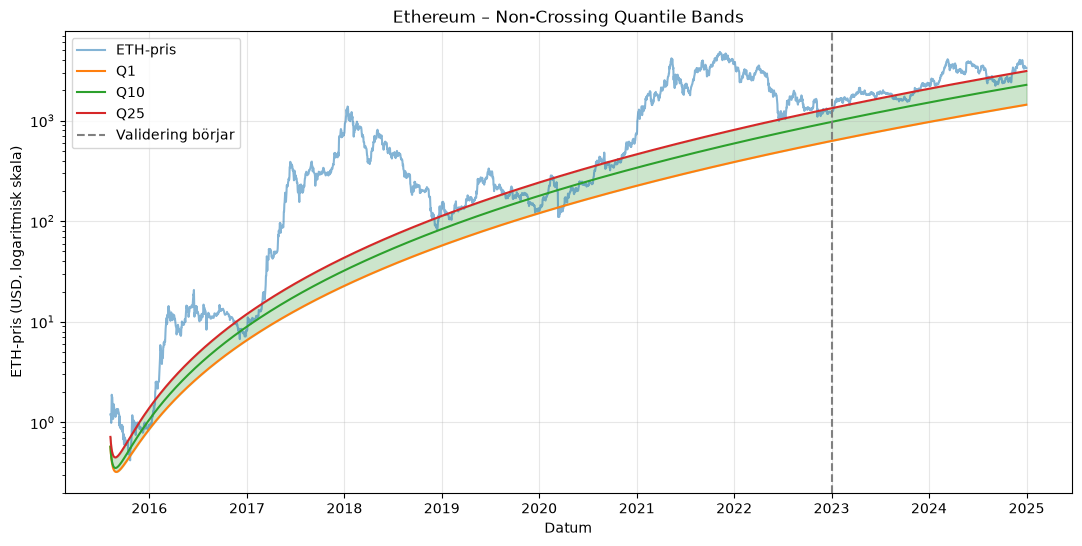

In [34]:

from scipy.optimize import linprog
from scipy.sparse import csr_matrix, eye, hstack

# 1. Förbered träningsdata
x_train = (
    np.log((cowen_train["Date"] - eth_launch).dt.days.to_numpy())
)
center_nc = x_train.mean()
x_train = x_train - center_nc

y_train = np.log10(cowen_train["ETH_Price"].to_numpy())

n = len(y_train)
k = len(levels)
m = n * k

# 2. Gemensam kurvatur med separata intercept och lutningar
design = np.zeros((m, 2*k + 1))

for j in range(k):
    rows = slice(j*n, (j+1)*n)
    design[rows, 2*j] = 1
    design[rows, 2*j+1] = x_train

design[:, -1] = np.tile(x_train**2, k)

# 3. Begränsa kurvornas ordning inom 2015–2024
# Endast datum används från valideringen, inga priser.
x_val = (
    np.log((cowen_val["Date"] - eth_launch).dt.days.to_numpy())
    - center_nc
)

endpoints = [x_train.min(), x_val.max()]
constraints = []

for j in range(k-1):
    for endpoint in endpoints:
        row = np.zeros(2*k + 1)
        row[2*j] = 1
        row[2*j+1] = endpoint
        row[2*(j+1)] = -1
        row[2*(j+1)+1] = -endpoint
        constraints.append(row)

A_ub = hstack([
    csr_matrix(np.array(constraints)),
    csr_matrix((len(constraints), 2*m))
], format="csr")

# 4. Gemensam optimering med Pinball Loss
A_eq = hstack([
    csr_matrix(design),
    eye(m, format="csr"),
    -eye(m, format="csr")
], format="csr")

objective = np.r_[
    np.zeros(2*k + 1),
    np.repeat(levels, n),
    np.repeat(1-levels, n)
]

bounds = (
    [(None, None)] * (2*k + 1)
    + [(0, None)] * (2*m)
)

result_nc = linprog(
    c=objective,
    A_eq=A_eq,
    b_eq=np.tile(y_train, k),
    A_ub=A_ub,
    b_ub=np.zeros(len(constraints)),
    bounds=bounds,
    method="highs"
)

if not result_nc.success:
    raise RuntimeError(result_nc.message)

coeff_nc = result_nc.x[:2*k + 1]

# 5. Funktion för att skapa band utan sortering
def predict_non_crossing(data):
    x = (
        np.log((data["Date"] - eth_launch).dt.days.to_numpy())
        - center_nc
    )

    return np.column_stack([
        coeff_nc[2*j]
        + coeff_nc[2*j+1] * x
        + coeff_nc[-1] * x**2
        for j in range(k)
    ])

# 6. Kontrollera korsningar
plot_df = pd.concat([
    cowen_train, cowen_val
]).sort_values("Date")

new_bands = predict_non_crossing(plot_df)

crossings = np.sum(
    np.any(np.diff(new_bands, axis=1) < -1e-8, axis=1)
)

print("Korsningsobservationer:", crossings)
print("Gemensam kurvatur:", round(coeff_nc[-1], 5))

# 7. Jämför gammal och ny modell på valideringsdata
old_coeffs, old_center = fit_shared_curvature(cowen_train)

_, old_val = predict_shared_curvature(
    cowen_val, old_coeffs, old_center
)
new_val = predict_non_crossing(cowen_val)

actual = np.log10(cowen_val["ETH_Price"].to_numpy())

results = []

for j, (name, q) in enumerate(zip(names, levels)):
    results.append({
        "Kvantil": name,
        "Tidigare Loss": mean_pinball_loss(
            actual, old_val[:, j], alpha=q
        ),
        "Non-Crossing Loss": mean_pinball_loss(
            actual, new_val[:, j], alpha=q
        ),
        "Coverage (%)": np.mean(
            actual < new_val[:, j]
        ) * 100
    })

display(pd.DataFrame(results).round(4))

# 8. Visualisera de nya banden
prices = 10**new_bands

plt.figure(figsize=(13, 6))

plt.plot(
    plot_df["Date"],
    plot_df["ETH_Price"],
    alpha=0.55,
    label="ETH-pris"
)

for j, name in enumerate(names):
    plt.plot(
        plot_df["Date"],
        prices[:, j],
        label=name
    )

plt.fill_between(
    plot_df["Date"],
    prices[:, 0],
    prices[:, 2],
    color="green",
    alpha=0.2
)

plt.axvline(
    cowen_val["Date"].min(),
    color="gray",
    linestyle="--",
    label="Validering börjar"
)

plt.yscale("log")
plt.title("Ethereum – Non-Crossing Quantile Bands")
plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Resultat och slutsats

Non-Crossing Constraints eliminerade samtliga korsningar mellan Q1, Q10 och Q25 under perioden 2015–2024.

Q25 uppnådde en valideringstäckning på 25,86 %, medan Q1 och Q10 fortfarande hade 0 %.

**Slutsats:** Bandens ordning är nu stabil inom det undersökta intervallet. Vi behöver fortfarande kontrollera modellens prediktiva kvalitet innan den kan godkännas.



### Walk-Forward Validation – Non-Crossing Shared Curvature

Vi utvärderar Non-Crossing Shared Curvature med Expanding Window under 2018–2022.

För varje valideringsår tränas modellen endast på tidigare historik. Non-Crossing Constraints införs vid varje ny modellträning.

Vi jämför Pinball Loss, Coverage och korsningar med den tidigare Shared Curvature-modellen från avsnitt 5.16.


Genomsnittliga resultat 2018–2022:


,Tidigare_Loss,NonCrossing_Loss,Tidigare_Coverage,NonCrossing_Coverage
Kvantil,,,,
Q1,0.0174,0.0196,10.5165,10.8453
Q10,0.0738,0.0762,27.5356,28.0837
Q25,0.1738,0.1713,40.9508,40.2946



Korsningar per år:


,År,Tidigare,Korsningar
0,2018,239,0
1,2019,0,0
2,2020,0,0
3,2021,0,0
4,2022,0,0


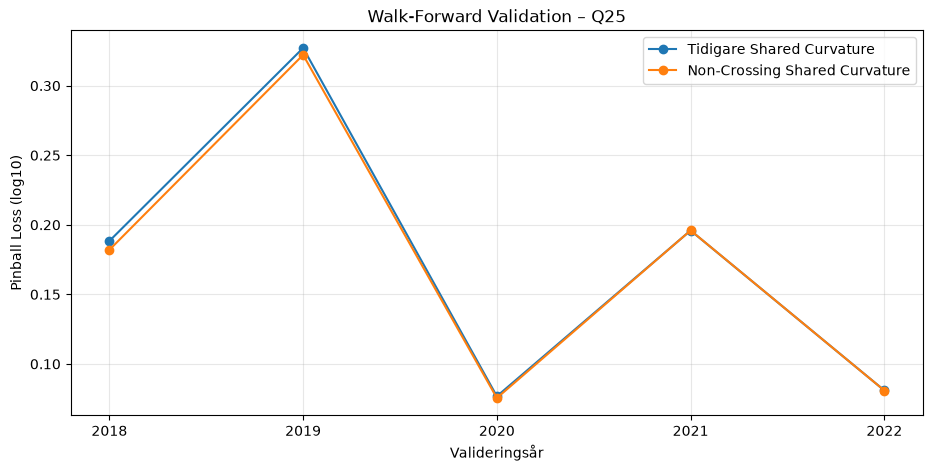

In [35]:

from scipy.optimize import linprog
from scipy.sparse import csr_matrix, eye, hstack
from sklearn.metrics import mean_pinball_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Träna Non-Crossing-modellen på en historisk period
def fit_nc_walkforward(train_fold, last_val_date):

    days = (train_fold["Date"] - eth_launch).dt.days.to_numpy()
    log_t = np.log(days)

    # Centrering baseras endast på träningsdata
    center = log_t.mean()
    x = log_t - center
    y = np.log10(train_fold["ETH_Price"].to_numpy())

    n = len(y)
    k = len(levels)
    m = n * k

    # Gemensam kurvatur, separata intercept och lutningar
    design = np.zeros((m, 2*k + 1))

    for j in range(k):
        rows = slice(j*n, (j+1)*n)
        design[rows, 2*j] = 1
        design[rows, 2*j+1] = x

    design[:, -1] = np.tile(x**2, k)

    # Non-Crossing Constraints från träningens start
    # till valideringsårets slut. Endast datum används.
    x_end = np.log(
        (last_val_date - eth_launch).days
    ) - center

    constraints = []

    for j in range(k-1):
        for endpoint in [x.min(), x_end]:

            row = np.zeros(2*k + 1)

            row[2*j] = 1
            row[2*j+1] = endpoint
            row[2*(j+1)] = -1
            row[2*(j+1)+1] = -endpoint

            constraints.append(row)

    constraints = np.array(constraints)

    A_ub = hstack([
        csr_matrix(constraints),
        csr_matrix((len(constraints), 2*m))
    ], format="csr")

    # Gemensam optimering med Pinball Loss
    A_eq = hstack([
        csr_matrix(design),
        eye(m, format="csr"),
        -eye(m, format="csr")
    ], format="csr")

    objective = np.r_[
        np.zeros(2*k + 1),
        np.repeat(levels, n),
        np.repeat(1-levels, n)
    ]

    bounds = (
        [(None, None)] * (2*k + 1)
        + [(0, None)] * (2*m)
    )

    result = linprog(
        c=objective,
        A_eq=A_eq,
        b_eq=np.tile(y, k),
        A_ub=A_ub,
        b_ub=np.zeros(len(constraints)),
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x[:2*k + 1], center


# 2. Walk-Forward Validation
nc_results = []
nc_crossings = []

for year in range(2018, 2023):

    train_fold = cowen_train[
        cowen_train["Date"].dt.year < year
    ].sort_values("Date")

    val_fold = cowen_train[
        cowen_train["Date"].dt.year == year
    ].sort_values("Date")

    # Träna modellen från början för varje år
    coeff, center = fit_nc_walkforward(
        train_fold,
        val_fold["Date"].max()
    )

    # Förutsägelser på det historiskt osedda året
    days = (val_fold["Date"] - eth_launch).dt.days.to_numpy()
    x = np.log(days) - center

    predictions = np.column_stack([
        coeff[2*j]
        + coeff[2*j+1] * x
        + coeff[-1] * x**2
        for j in range(len(levels))
    ])

    actual = np.log10(val_fold["ETH_Price"].to_numpy())

    # Kontrollera korsningar utan Quantile Rearrangement
    crossings = np.sum(
        np.any(np.diff(predictions, axis=1) < -1e-8, axis=1)
    )

    nc_crossings.append({
        "År": year,
        "Korsningar": int(crossings)
    })

    # Utvärdera samtliga kvantiler
    for j, (name, q) in enumerate(zip(names, levels)):

        nc_results.append({
            "År": year,
            "Kvantil": name,
            "Pinball Loss": mean_pinball_loss(
                actual, predictions[:, j], alpha=q
            ),
            "Coverage (%)": np.mean(
                actual < predictions[:, j]
            ) * 100
        })


# 3. Jämför med tidigare Shared Curvature (5.16)
wf_nc_df = pd.DataFrame(nc_results)

comparison_nc = wf_cowen_df.merge(
    wf_nc_df,
    on=["År", "Kvantil"],
    suffixes=("_Tidigare", "_NonCrossing")
)

print("Genomsnittliga resultat 2018–2022:")

summary_nc = comparison_nc.groupby("Kvantil").agg(
    Tidigare_Loss=("Pinball Loss_Tidigare", "mean"),
    NonCrossing_Loss=("Pinball Loss_NonCrossing", "mean"),
    Tidigare_Coverage=("Coverage (%)_Tidigare", "mean"),
    NonCrossing_Coverage=("Coverage (%)_NonCrossing", "mean")
)

display(summary_nc.round(4))


# 4. Jämför korsningar per år
cross_nc = pd.DataFrame(nc_crossings)

cross_nc["Tidigare"] = [
    row["Korsningar"] for row in wf_crossings
]

print("\nKorsningar per år:")
display(
    cross_nc[["År", "Tidigare", "Korsningar"]]
)


# 5. Visualisera Q25 Pinball Loss
q25_nc = comparison_nc[
    comparison_nc["Kvantil"] == "Q25"
]

plt.figure(figsize=(11, 5))

plt.plot(
    q25_nc["År"],
    q25_nc["Pinball Loss_Tidigare"],
    marker="o",
    label="Tidigare Shared Curvature"
)

plt.plot(
    q25_nc["År"],
    q25_nc["Pinball Loss_NonCrossing"],
    marker="o",
    label="Non-Crossing Shared Curvature"
)

plt.title("Walk-Forward Validation – Q25")
plt.xlabel("Valideringsår")
plt.ylabel("Pinball Loss (log10)")
plt.xticks(range(2018, 2023))
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Resultat och slutsats

Non-Crossing Constraints eliminerade samtliga korsningar under Walk-Forward Validation (2018–2022).

Q25 Pinball Loss förbättrades marginellt från 0,1738 till 0,1713, medan Q1 och Q10 försämrades något.

**Slutsats:** Modellen har fått stabilare bandstruktur utan betydande försämring av träffsäkerheten. Kvantiltäckningen är dock fortfarande ojämn, vilket behöver beaktas vid fortsatt utvärdering.



### Backtesting – Historical Accumulation Zones

Vi undersöker om köp vid eller under Q25 historiskt har gett högre framtida avkastning än köp över Q25.

Modellen tränas med Expanding Window och genererar historiska band utan att använda framtida prisinformation.

Vi jämför avkastning efter 180 och 365 dagar med både medelvärde och median.

Analysen är explorativ. Slutlig testdata från 2025–2026 används inte.



Framtida avkastning efter 180 dagar (%):


,Antal,Medelvärde,Median
Signal,,,
Vid/under Q25,836,73.73,59.67
Över Q25,1541,30.77,2.61



Framtida avkastning efter 365 dagar (%):


,Antal,Medelvärde,Median
Signal,,,
Vid/under Q25,836,304.64,71.47
Över Q25,1356,76.18,11.43



180 dagars avkastning per år:


,År,Signal,Antal,Median
0,2018,Vid/under Q25,143,-19.86
1,2018,Över Q25,222,-68.48
2,2019,Vid/under Q25,365,12.12
3,2020,Vid/under Q25,228,141.87
4,2020,Över Q25,138,339.74
5,2021,Över Q25,365,42.81
6,2022,Över Q25,365,-4.56
7,2023,Vid/under Q25,100,88.82
8,2023,Över Q25,265,17.92
9,2024,Över Q25,186,-8.33


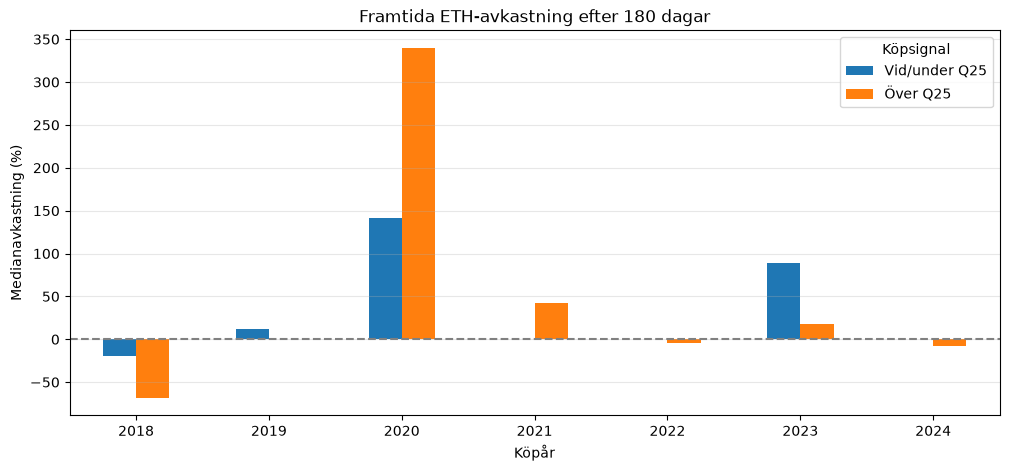

In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Historisk data fram till slutet av 2024
history = (
    pd.concat([cowen_train, cowen_val])
    .sort_values("Date")
    .reset_index(drop=True)
)

# Kontrollera att vi har sammanhängande daglig data
assert history["Date"].is_unique
assert history["Date"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all()

# 2. Beräkna framtida avkastning
# Dessa värden används ENDAST vid utvärdering
for days in [180, 365]:
    history[f"Return_{days}D"] = (
        history["ETH_Price"].shift(-days)
        / history["ETH_Price"] - 1
    ) * 100

# 3. Skapa historiska band med Expanding Window
backtest_folds = []

for year in range(2018, 2025):

    train_fold = history[
        history["Date"].dt.year < year
    ].copy()

    val_fold = history[
        history["Date"].dt.year == year
    ].copy()

    # Träna enbart på tidigare år
    coeff, center = fit_nc_walkforward(
        train_fold,
        val_fold["Date"].max()
    )

    # Förutsäg årets tre kvantilkurvor
    days = (
        val_fold["Date"] - eth_launch
    ).dt.days.to_numpy()

    x = np.log(days) - center

    log_bands = np.column_stack([
        coeff[2*j]
        + coeff[2*j+1] * x
        + coeff[-1] * x**2
        for j in range(len(levels))
    ])

    # Kontrollera ordningen utan sortering
    assert np.all(np.diff(log_bands, axis=1) >= -1e-8)

    bands = 10 ** log_bands

    for j, name in enumerate(names):
        val_fold[name] = bands[:, j]

    # Definiera köpzon: pris vid eller under Q25
    val_fold["Signal"] = np.where(
        val_fold["ETH_Price"] <= val_fold["Q25"],
        "Vid/under Q25",
        "Över Q25"
    )

    val_fold["År"] = year

    backtest_folds.append(val_fold)

backtest_df = pd.concat(
    backtest_folds, ignore_index=True
)

# 4. Jämför framtida avkastning för 180 och 365 dagar
for horizon in [180, 365]:

    column = f"Return_{horizon}D"

    # Exkludera observationer utan full framtida period
    valid = backtest_df.dropna(subset=[column])

    summary = (
        valid.groupby("Signal")[column]
        .agg(
            Antal="count",
            Medelvärde="mean",
            Median="median"
        )
        .round(2)
    )

    print(f"\nFramtida avkastning efter {horizon} dagar (%):")
    display(summary)

# 5. Undersök resultat per år (180 dagar)
valid_180 = backtest_df.dropna(
    subset=["Return_180D"]
)

yearly_summary = (
    valid_180.groupby(["År", "Signal"])["Return_180D"]
    .agg(Antal="count", Median="median")
    .reset_index()
)

print("\n180 dagars avkastning per år:")
display(yearly_summary.round(2))

# 6. Visualisera medianavkastning per år
pivot = yearly_summary.pivot(
    index="År",
    columns="Signal",
    values="Median"
)

pivot.plot(kind="bar", figsize=(12, 5))

plt.title("Framtida ETH-avkastning efter 180 dagar")
plt.xlabel("Köpår")
plt.ylabel("Medianavkastning (%)")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(rotation=0)
plt.legend(title="Köpsignal")
plt.grid(axis="y", alpha=0.3)
plt.show()



### Resultat och slutsats

Backtestingen visar att köp vid eller under Q25 historiskt gav högre medianavkastning efter både 180 dagar (59,67 % mot 2,61 %) och 365 dagar (71,47 % mot 11,43 %).

Resultaten varierade dock mellan åren. Under 2020 presterade köp över Q25 bättre, och vissa år saknade helt köpsignaler inom zonen.

**Slutsats:** Ackumulationsbandet visar potential att identifiera historiskt gynnsamma köpområden, men resultaten behöver kontrolleras för marknadscykler och överlappande observationer.
